# Fig. 1–3 的小组件：Python 画法

论文里三张示意图（Fig. 1 双层结构、Fig. 2 决策地形、Fig. 3 方法框架）中的每个小组件，都是一张按最终尺寸画的 matplotlib 小图。这个 notebook 把它们的画图代码整理出来，**每个组件一个代码格**。

- 先运行第一格「公共设置」。Fig. 3 的每一格之后都能单独运行；Fig. 1、Fig. 2 两节里的格子要按顺序运行。
- 每格画完会显示出来，同时在 `out/` 文件夹里存一份 PNG（600 dpi）和 SVG。
- 坐标单位都是毫米，画布就是组件在论文里的实际大小，所以线宽、字号就是印出来的大小。
- 需要 numpy、matplotlib（3.8 或更新）、scipy、Pillow。Fig. 2 的地形用到 `data/fig2_landscape.npz`（模型真实算出来的结果），要和本文件放在一起。
- 和论文原图的差别：原图小组件里的文字是 LaTeX 排的，这里改用 matplotlib 自带的 STIX 数学字体，不用装 LaTeX；各个框、框标题、编号圆点和框之间的箭头是在 PPT 里加的，这里只在需要时补上几行字。

In [1]:
# ===== 公共设置：先运行这一格 =====
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import patheffects
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb
from matplotlib.patches import Circle, Ellipse, FancyBboxPatch, Polygon, Rectangle

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["Times New Roman"],   # 和论文正文一样用 Times
    "mathtext.fontset": "stix",                                  # 公式用 STIX 字体，不用装 LaTeX
    "font.size": 6.8,                                            # 印出来 6.8 pt
    "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "svg.fonttype": "path",                                      # SVG 里的字转成轮廓，换电脑打开也一样
    "figure.dpi": 250,                                           # 只影响 notebook 里显示的大小
})
OUT = Path("out")                                                # 每个组件存一份 PNG 和 SVG
OUT.mkdir(exist_ok=True)

# ---- 颜色 ----
EV, AI, ES = "#c4546e", "#6a70b6", "#a88a3a"                     # 三类聚合商：电动汽车、算力、储能
LEARN, KNOWN, SEARCH = "#2b8a7a", "#1f5aa6", "#d08a1e"           # 步骤框：学习（绿）、已知物理（蓝）、搜索（橙）
INK, INK_2, AXIS, VIOL = "#1a1a1a", "#4d4d4d", "#8b909a", "#c0392b"   # 文字、次要文字、坐标轴、越限


def mix(a, b, w):
    """两个颜色按比例混合：w = 0 是 a，w = 1 是 b。"""
    return tuple((1 - w) * np.array(to_rgb(a)) + w * np.array(to_rgb(b)))


def tint(c, w):                                                  # 掺白，变浅
    return mix(c, "#ffffff", w)


def shade(c, w):                                                 # 掺黑，变深
    return mix(c, "#000000", w)


# ---- 画布、保存、文字、箭头 ----
def canvas(w, h, y_down=False, x0=0.0, y0=0.0):
    """开一张 w × h 毫米的画布，坐标单位就是毫米。y_down=True 时 y 轴朝下（和 PPT 一样）；
    x0、y0 是画布左边和上边（y_down）或下边的坐标。"""
    fig = plt.figure(figsize=(w / 25.4, h / 25.4))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(x0, x0 + w)
    ax.set_ylim((y0 + h, y0) if y_down else (y0, y0 + h))
    ax.set_aspect("equal")
    ax.axis("off")
    fig.patch.set_alpha(0)
    return fig, ax


def done(fig, name, svg=True):
    """存成 out/name.png（600 dpi、透明背景）和 out/name.svg，再在下面显示出来。"""
    fig.savefig(OUT / f"{name}.png", dpi=600, transparent=True)
    if svg:
        fig.savefig(OUT / f"{name}.svg", dpi=600, transparent=True)
    fig.patch.set_facecolor("white")
    fig.patch.set_alpha(1)
    plt.show()


def text(ax, x, y, s, size=6.8, color=INK, ha="center", va="center", bold=False, italic=False, halo=False,
         bbox=None, z=63, **kw):
    """写一段字。halo=True 加一圈白边，压在图上也看得清；bbox 给一个底框。"""
    t = ax.text(x, y, s, fontsize=size, color=color, ha=ha, va=va, zorder=z,
                fontweight="bold" if bold else "normal", fontstyle="italic" if italic else "normal", **kw)
    if halo:
        t.set_path_effects([patheffects.Stroke(linewidth=1.8, foreground="white"),
                            patheffects.PathPatchEffect(facecolor=color, edgecolor="none", linewidth=0)])
    if bbox:
        t.set_bbox(bbox)
    return t


def arrow(ax, p0, p1, color=AXIS, lw=0.45, head=0.9, width=0.62, z=3, dashed=False):
    """一段直线加一个三角形箭头，箭头的长和宽都用毫米给。"""
    p0, p1 = np.asarray(p0, float), np.asarray(p1, float)
    u = (p1 - p0) / np.hypot(*(p1 - p0))
    n = np.array([-u[1], u[0]])
    base = p1 - u * head
    ax.plot(*zip(p0, base), color=color, lw=lw, zorder=z, solid_capstyle="butt",
            ls=(0, (2.2, 1.4)) if dashed else "-")
    ax.add_patch(Polygon([p1, base + n * width / 2, base - n * width / 2], closed=True, fc=color, ec="none",
                         zorder=z))


# ---- 立体块：斜投影 + 三种明暗（档案卡片、排序立柱会用到）----
class Pr:
    """斜投影：x 往右，深度 d 往右上（每单位往右 kx、往上 ky），高度 z 往上；返回画布上的毫米坐标。"""

    def __init__(self, x0, y0, kx=0.55, ky=0.62):
        self.x0, self.y0, self.kx, self.ky = x0, y0, kx, ky

    def __call__(self, x, d, z):
        return (self.x0 + x + d * self.kx, self.y0 + d * self.ky + z)

    def quad(self, x0, x1, d0, d1, z):                           # 高度 z 处的一块水平矩形
        return [self(x0, d0, z), self(x1, d0, z), self(x1, d1, z), self(x0, d1, z)]


def poly(ax, pts, fc, z, ec="none", lw=0.0, alpha=1.0):
    ax.add_patch(Polygon(pts, closed=True, fc=fc, ec=ec, lw=lw, alpha=alpha, zorder=z, joinstyle="round"))


def line(ax, pts, color, lw, z, alpha=1.0):
    pts = np.asarray(pts)
    ax.plot(pts[:, 0], pts[:, 1], color=color, lw=lw, zorder=z, alpha=alpha, solid_joinstyle="round",
            solid_capstyle="round")


def box(ax, pr, x, d, z, w, dep, h, col, zo, top=None, front=None, side=None, hl=True, ec=None, lw=0.0):
    """打了光的长方体：右侧面最暗、正面本色、顶面最亮，亮边描一道白线。top=False 不画顶面。"""
    front = col if front is None else front
    side = shade(col, 0.2) if side is None else side
    top = tint(col, 0.5) if top is None else top
    F = [pr(x, d, z), pr(x + w, d, z), pr(x + w, d, z + h), pr(x, d, z + h)]
    R = [pr(x + w, d, z), pr(x + w, d + dep, z), pr(x + w, d + dep, z + h), pr(x + w, d, z + h)]
    poly(ax, R, side, zo, ec=ec or "none", lw=lw)
    poly(ax, F, front, zo + 0.01, ec=ec or "none", lw=lw)
    if top is not False:
        poly(ax, pr.quad(x, x + w, d, d + dep, z + h), top, zo + 0.02, ec=ec or "none", lw=lw)
    if hl:
        line(ax, [pr(x, d, z + h), pr(x + w, d, z + h), pr(x + w, d + dep, z + h)], "white", 0.3, zo + 0.03, 0.85)


def shadow(ax, pr, x, d, w, dep, h, zo, k=0.16, alpha=0.11):
    """落地阴影：往右后方拖，两层叠出柔和的边。"""
    for grow, a in ((1.0, alpha * 0.55), (0.55, alpha * 0.75)):
        s = k * h * grow
        poly(ax, pr.quad(x + 0.05, x + w + s, d + 0.08, d + dep + s * 0.8, 0), "#2e3448", zo, alpha=a)


# ---- Fig. 3 共用：加价信号、随机特征上的贝叶斯回归 ----
ADDER_CMAP = LinearSegmentedColormap.from_list("adder", ["#fff8ec", "#fbdcae", "#f0b162", "#d08a1e", "#8f520e"])
ABAR = 0.15                                                      # 加价上限（美元/kWh）：颜色从 0 画到 ABAR
A_SHOW = np.array([[0.02, 0.05, 0.09, 0.06, 0.03, 0.01],         # 示意用的加价信号：
                   [0.04, 0.10, 0.13, 0.08, 0.05, 0.02],         # 5 条资源母线（行）× 6 个小时（列）
                   [0.00, 0.03, 0.07, 0.11, 0.06, 0.03],
                   [0.06, 0.12, 0.15, 0.10, 0.04, 0.02],
                   [0.08, 0.14, 0.12, 0.07, 0.05, 0.01]])


@np.errstate(all="ignore")
def rff_blr(xo, yo, xs, L=60, ell=0.14, gamma=1.0, sigma=0.06, seed=0):
    """随机傅里叶特征上的贝叶斯线性回归（一维），真的算一遍：返回后验均值、标准差和 3 条后验采样。"""
    rng = np.random.default_rng(seed)
    th, be = rng.normal(0, 1 / ell, L), rng.uniform(0, 2 * np.pi, L)
    phi = lambda x: np.sqrt(2 / L) * np.cos(np.outer(x, th) + be)
    Po = phi(xo)
    Sig = np.linalg.inv(Po.T @ Po / sigma**2 + gamma * np.eye(L))     # 权重的后验协方差
    mw = Sig @ Po.T @ yo / sigma**2                                   # 权重的后验均值
    Ps = phi(xs)
    mean = Ps @ mw
    sd = np.sqrt(np.einsum("ij,jk,ik->i", Ps, Sig, Ps))
    Lc = np.linalg.cholesky(Sig + 1e-10 * np.eye(L))
    draws = [Ps @ (mw + Lc @ rng.normal(size=L)) for _ in range(3)]
    return mean, sd, draws


print("设置完成，图会存到 out/ 文件夹")

设置完成，图会存到 out/ 文件夹


## Fig. 3 方法框架图

每个组件的标题写了它在图里的位置。小组件里的字（比如 buses、hours）是画进图里的；框的标题、编号和框之间的箭头是在 PPT 里加的。

### ① 加价信号热力图板（左上，40 × 17 mm）
每格按数值查颜色，画成斜着的平行四边形；最前一行和最右一列往下拉出板厚，颜色掺黑。

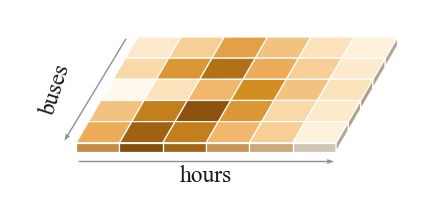

In [2]:
def field(ax, A, x0, y0, cw, dx, dy, thick, edge="#ffffff"):
    """A 的行 = 母线（第 0 行在最里面），列 = 小时；返回角点函数 P(c, r)。"""
    nb, nh = A.shape
    norm = Normalize(0, ABAR)                                    # 数值先缩放到 0–1，再查颜色
    P = lambda c, r: np.array([x0 + c * cw + r * dx, y0 + r * dy])   # 第 c 列、往里第 r 行的角点（r = 0 最前）
    for i in range(nb):                                          # 顶面：从里往外，每格一个平行四边形
        r = nb - 1 - i
        for c in range(nh):
            ax.add_patch(Polygon([P(c, r), P(c + 1, r), P(c + 1, r + 1), P(c, r + 1)], closed=True,
                                 fc=ADDER_CMAP(norm(A[i, c])), ec=edge, lw=0.35, zorder=3, joinstyle="round"))
    for c in range(nh):                                          # 正面：最前一行往下拉出板厚，掺黑 18%
        p, q = P(c, 0), P(c + 1, 0)
        ax.add_patch(Polygon([p, q, q - (0, thick), p - (0, thick)], closed=True,
                             fc=shade(ADDER_CMAP(norm(A[nb - 1, c])), 0.18), ec=edge, lw=0.35, zorder=2))
    for r in range(nb):                                          # 右侧面：最右一列往下拉，掺黑 30%
        p, q = P(nh, r), P(nh, r + 1)
        ax.add_patch(Polygon([p, q, q - (0, thick), p - (0, thick)], closed=True,
                             fc=shade(ADDER_CMAP(norm(A[nb - 1 - r, nh - 1])), 0.3), ec=edge, lw=0.35, zorder=2))
    return P


fig, ax = canvas(40, 17)
P = field(ax, A_SHOW, x0=5.2, y0=5.0, cw=4.4, dx=1.25, dy=2.15, thick=0.9)
a, b = P(0, 0) + (-1.2, 0.2), P(0, 5) + (-1.2, -0.2)            # 不画坐标轴，用带箭头的文字说明方向
arrow(ax, b, a, AXIS, 0.4, head=0.7, width=0.5)
text(ax, a[0] - 0.9, (a[1] + b[1]) / 2, "buses", rotation=72)
a, b = P(0, 0) - (0, 1.9), P(6, 0) - (0, 1.9)
arrow(ax, a + (0.2, 0), b - (0.2, 0), AXIS, 0.4, head=0.7, width=0.5)
text(ax, (a[0] + b[0]) / 2, a[1] - 0.35, "hours", va="top")
done(fig, "fig3_01_adder_signal")

### ② 私有聚合商（左栏，每行 44 × 8.2 mm）
自己那一行价格 → 黑箱（同类有好几家，就在后面叠几层）→ 推演出的几条分段响应。

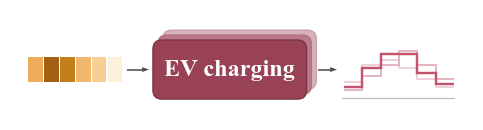

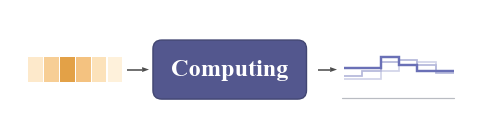

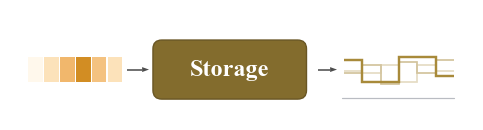

In [3]:
AGG = {  # 颜色、后面叠几层、用加价信号的第几行、三条响应（每小时的高低，0–1）
    "ev": (EV, 2, 4, [[0.20, 0.55, 0.80, 0.80, 0.45, 0.25], [0.15, 0.40, 0.60, 0.85, 0.60, 0.35],
                      [0.30, 0.60, 0.70, 0.55, 0.35, 0.20]]),
    "ai": (AI, 0, 0, [[0.55, 0.55, 0.75, 0.60, 0.50, 0.50], [0.40, 0.50, 0.65, 0.70, 0.60, 0.45],
                      [0.35, 0.35, 0.50, 0.60, 0.65, 0.50]]),
    "es": (ES, 0, 2, [[0.70, 0.30, 0.30, 0.75, 0.75, 0.40], [0.45, 0.60, 0.25, 0.65, 0.45, 0.70],
                      [0.50, 0.45, 0.60, 0.30, 0.60, 0.50]]),
}


def step_line(ax, x0, x1, base, height, levels, color, lw=0.6, z=3):
    """分段常数的折线：每小时一段水平线。"""
    xs = np.linspace(x0, x1, len(levels) + 1)
    X, Y = np.repeat(xs, 2)[1:-1], base + height * np.repeat(levels, 2)
    ax.plot(X, Y, color=color, lw=lw, zorder=z, solid_joinstyle="miter", solid_capstyle="butt")


for key, name in (("ev", "EV charging"), ("ai", "Computing"), ("es", "Storage")):
    color, copies, row, resp = AGG[key]
    w, h = 44, 8.2
    fig, ax = canvas(w, h)
    cy = h / 2 - 0.5                                             # 这一行的中线
    norm = Normalize(0, ABAR)
    cw, ch, g = 1.5, 2.6, 0.12
    for c in range(6):                                           # 自己那一行加价：6 个小色块
        ax.add_patch(Rectangle((0.3 + c * (cw + g), cy - ch / 2), cw, ch, fc=ADDER_CMAP(norm(A_SHOW[row, c])),
                               ec="none", zorder=3))
    arrow(ax, (10.4, cy), (12.6, cy), INK_2, 0.45, head=0.7, width=0.5)
    bx, bw, bh = 13.0, 15.6, 6.0                                 # 黑箱的位置和大小
    dark = shade(color, 0.22)
    for k in range(copies, -1, -1):                              # 同类的其他几家叠在后面，越往后越淡
        o = 0.5 * k
        ax.add_patch(FancyBboxPatch((bx + o, cy - bh / 2 + o), bw, bh, boxstyle="round,pad=0,rounding_size=0.9",
                                    fc=tint(dark, 0.3 * k), ec=tint(dark, 0.25 * k) if k else shade(dark, 0.2),
                                    lw=0.4, zorder=3 - 0.1 * k))
    text(ax, bx + bw / 2, cy, name, 7.0, color="white", bold=True)   # 原图里这行字是 PPT 文字
    arrow(ax, (bx + bw + 1.2, cy), (bx + bw + 3.1, cy), INK_2, 0.45, head=0.7, width=0.5)
    x0, x1, base, ht = bx + bw + 3.6, w - 0.4, cy - 2.9, 5.6
    ax.plot([x0, x1], [base, base], color=tint(AXIS, 0.4), lw=0.35, zorder=1)
    for k, lv in enumerate(resp):                                # 三条响应：第一条最深，其余变浅
        step_line(ax, x0 + 0.2, x1, base, ht, np.array(lv), color if k == 0 else tint(color, 0.3 + 0.2 * k),
                  lw=0.7 if k == 0 else 0.5, z=3 - 0.1 * k)
    done(fig, f"fig3_02_aggregator_{key}")

### ③ 响应档案（左下，46.3 × 15.6 mm）
玻璃托盘里竖着放的档案卡片，最新的两张在前、颜色最实，越旧越淡；最前一张上画着三类聚合商的响应。

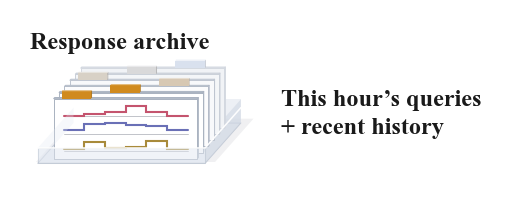

In [4]:
def profiles(kind, n, seed, m=90):
    """某一类聚合商推演出的 n 条响应（平滑的示意曲线，0–1）。"""
    rng = np.random.default_rng(seed)
    x = np.linspace(0, 1, m)
    win = np.sin(np.pi * x) ** 0.55
    out = []
    for _ in range(n):
        if kind == "ev":
            c = 0.6 + rng.normal(0, 0.05)
            y = (0.95 + 0.12 * rng.standard_normal()) * np.exp(-0.5 * ((x - c) / 0.12) ** 2) \
                + 0.28 * np.exp(-0.5 * ((x - 0.24 - rng.normal(0, 0.03)) / 0.08) ** 2)
        elif kind == "ai":
            y = 0.42 + 0.32 * np.exp(-0.5 * ((x - 0.5 - rng.normal(0, 0.05)) / 0.2) ** 2) \
                + 0.11 * np.sin(2 * np.pi * (1.6 * x + rng.uniform()))
        else:
            y = (0.78 + 0.1 * rng.standard_normal()) * np.exp(-0.5 * ((x - 0.27 - rng.normal(0, 0.04)) / 0.09) ** 2) \
                + (0.85 + 0.1 * rng.standard_normal()) * np.exp(-0.5 * ((x - 0.72 - rng.normal(0, 0.04)) / 0.1) ** 2)
        out.append(np.clip(y, 0, None) * win)
    out = np.array(out)
    return out / out.max()


def hourly(kind, n, seed):
    """同样的响应，按 6 个小时取平均。"""
    P = profiles(kind, n, seed, m=6 * 15)
    return P.reshape(n, 6, 15).mean(axis=2) / P.max()


fig, ax = canvas(46.3, 15.6)
pr = Pr(1.3, 1.5, 0.55, 0.62)
W_, D_, n = 17.0, 6.6, 6                                         # 托盘的宽和深；6 张卡片
cw, ch, ct = 14.6, 6.1, 0.18                                     # 卡片的宽、高、厚
xc = (W_ - cw) / 2
ds = [0.75 + k * 1.0 for k in range(n)]                          # 每张卡片的深度，0 号（最新）在最前
poly(ax, pr.quad(-0.3, W_ + 0.9, 0.2, D_ + 0.7, 0), "#2e3448", 0.5, alpha=0.07)        # 托盘的影子
poly(ax, pr.quad(0, W_, 0, D_, 0), "#e8ecf2", 1, ec="#c3cad5", lw=0.3)                  # 托盘底
wall_h = 2.4                                                     # 后壁和右壁：半透明的玻璃
poly(ax, [pr(0, D_, 0), pr(W_, D_, 0), pr(W_, D_, wall_h), pr(0, D_, wall_h)], "#dfe5ee", 1.2, alpha=0.55)
poly(ax, [pr(W_, 0, 0), pr(W_, D_, 0), pr(W_, D_, wall_h), pr(W_, 0, wall_h)], "#cdd5e1", 1.3, alpha=0.55)
zo = 2.0
for k in range(n - 1, -1, -1):                                   # 卡片从后往前画，越旧越淡
    d = ds[k]
    age = 0.0 if k < 2 else (k - 1) / (n - 2)
    face = mix("#ffffff", "#f1f3f6", age)
    edge = mix("#a9b2c0", "#d3d8e0", age)
    box(ax, pr, xc, d, 0, cw, ct, ch, face, zo, top=mix("#eef1f5", "#f6f7f9", age), side="#cfd5de",
        ec=edge, lw=0.28, hl=False)
    tx = xc + 0.8 + (k % 3) * 4.4                                # 卡片上的索引标签，左右错开
    tc = mix(SEARCH, "#d9dde4", 0.0 if k < 2 else 0.55 + 0.1 * k)
    box(ax, pr, tx, d, ch, 3.0, ct, 0.75, tc, zo + 0.05, top=tint(tc, 0.4), side=shade(tc, 0.15), hl=False)
    if k == 0:                                                   # 最前一张卡片：三类聚合商的响应
        for j, (kname, col) in enumerate((("ev", EV), ("ai", AI), ("es", ES))):
            v = hourly(kname, 1, 97 + j)[0]
            base = ch - 1.25 - 1.75 * j
            xs = np.linspace(xc + 1.0, xc + cw - 1.0, 7)
            sx = np.repeat(xs, 2)[1:-1]
            sz = base - 0.55 + 1.15 * np.repeat(v, 2)
            ax.plot([pr(x_, d, 0)[0] for x_ in sx], [pr(0, d, z_)[1] for z_ in sz], color=col, lw=0.6,
                    zorder=zo + 0.1, solid_joinstyle="miter")
            line(ax, [pr(xc + 1.0, d, base - 0.55), pr(xc + cw - 1.0, d, base - 0.55)], tint(AXIS, 0.4), 0.25,
                 zo + 0.09)
    zo += 1
fw = 1.55                                                        # 托盘矮矮的前壁：玻璃，顶边一道亮线
poly(ax, [pr(0, 0, 0), pr(W_, 0, 0), pr(W_, 0, fw), pr(0, 0, fw)], "#e3e9f2", zo, alpha=0.5, ec="#b5bfcd", lw=0.3)
line(ax, [pr(0, 0, fw), pr(W_, 0, fw), pr(W_, D_, fw)], "white", 0.45, zo + 0.1, 0.95)
poly(ax, [pr(0, 0, 0), pr(0, D_, 0), pr(0, D_, fw), pr(0, 0, fw)], "#e3e9f2", zo - 0.5, alpha=0.3)
text(ax, 0.53, 13.71, "Response archive", 7.0, bold=True, ha="left")      # 这三行原图里是 PPT 文字
text(ax, 26.03, 7.955, "This hour’s queries", 7.0, bold=True, ha="left")
text(ax, 26.03, 5.075, "+ recent history", 7.0, bold=True, ha="left")
done(fig, "fig3_03_response_archive")

### ④ 学到的响应曲面（中栏，每个 33 × 10.5 mm）
函数 z = f(x, y) 在网格上取点，相邻四点围成半透明小四边形，从后往前铺；前沿粗线是学到的平滑模型，虚线台阶是线性规划真正给出的响应，圆点是查询过的点。

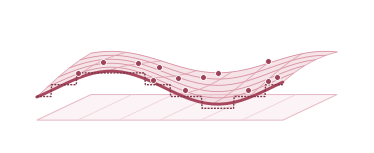

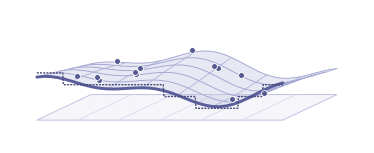

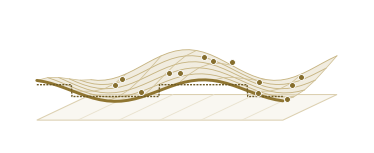

In [5]:
SURF = {  # 颜色和曲面的高度函数（示意）
    "ev": (EV, lambda x, y: 0.55 + 0.28 * np.sin(2 * np.pi * (1.15 * x + 0.25 * y) - 0.6) * (1 - 0.35 * y)),
    "ai": (AI, lambda x, y: 0.5 + 0.18 * np.sin(2 * np.pi * (0.9 * x - 0.2 * y) + 0.8) + 0.1 * np.cos(2 * np.pi * 2 * x)),
    "es": (ES, lambda x, y: 0.5 + 0.26 * np.sin(2 * np.pi * (1.4 * x + 0.4 * y) + 1.9) * (0.7 + 0.3 * y)),
}
W, DX, DY, HZ, x0, y0 = 25.0, 5.5, 2.6, 6.0, 1.2, 0.8
proj = lambda x, y, z: (x0 + x * W + y * DX, y0 + y * DY + z * HZ)   # 斜投影：深度 y 往右上，高度 z 往上

for key, (color, f) in SURF.items():
    fig, ax = canvas(33, 10.5)
    floor = [proj(0, 0, 0), proj(1, 0, 0), proj(1, 1, 0), proj(0, 1, 0)]
    ax.add_patch(Polygon(floor, closed=True, fc=tint(color, 0.93), ec=tint(color, 0.6), lw=0.3, zorder=1))
    for g in np.linspace(0, 1, 7)[1:-1]:
        ax.plot(*zip(proj(g, 0, 0), proj(g, 1, 0)), color=tint(color, 0.75), lw=0.25, zorder=1.1)
    nx, ny = 36, 6
    xs, ys = np.linspace(0, 1, nx), np.linspace(0, 1, ny)
    Z = np.array([[f(x, y) for x in xs] for y in ys])
    for j in range(ny - 2, -1, -1):                              # 半透明小四边形，从后往前铺
        for i in range(nx - 1):
            q = [proj(xs[i], ys[j], Z[j, i]), proj(xs[i + 1], ys[j], Z[j, i + 1]),
                 proj(xs[i + 1], ys[j + 1], Z[j + 1, i + 1]), proj(xs[i], ys[j + 1], Z[j + 1, i])]
            ax.add_patch(Polygon(q, closed=True, fc=tint(color, 0.62), ec="none", alpha=0.42,
                                 zorder=2 + (ny - j) * 0.01))
    for j in range(ny):                                          # 网格线：沿 x 每条都画，沿深度隔 5 列画一条
        p = np.array([proj(x, ys[j], Z[j, i]) for i, x in enumerate(xs)])
        ax.plot(p[:, 0], p[:, 1], color=tint(color, 0.35), lw=0.25, zorder=2.2)
    for i in range(0, nx, 5):
        p = np.array([proj(xs[i], y, Z[j, i]) for j, y in enumerate(ys)])
        ax.plot(p[:, 0], p[:, 1], color=tint(color, 0.45), lw=0.22, zorder=2.2)
    front = np.array([proj(x, 0, Z[0, i]) for i, x in enumerate(xs)])   # 前沿：学到的平滑模型
    ax.plot(front[:, 0], front[:, 1], color=shade(color, 0.15), lw=0.85, zorder=3)
    step = lambda x, y: np.round(f(x, y) * 5) / 5                # 线性规划真正给出的是一级级台阶
    st = np.array([proj(x, 0, step(x, 0)) for x in np.linspace(0, 1, 400)])
    ax.plot(st[:, 0], st[:, 1], color=shade(color, 0.35), lw=0.4, ls=(0, (1.4, 0.9)), zorder=3.1)
    rng = np.random.default_rng({"ev": 1, "ai": 2, "es": 4}[key])
    for a, b in zip(rng.uniform(0.04, 0.96, 13), rng.uniform(0.0, 0.95, 13)):   # 查询过的点
        ax.plot(*proj(a, b, step(a, b)), marker="o", ms=1.7, mfc=shade(color, 0.2), mec="#ffffff", mew=0.25,
                zorder=3.2)
    done(fig, f"fig3_04_learned_surface_{key}")

### ⑤ 随机特征 → 特征矩阵 φ(ξ)（中栏，35 × 12.5 mm）
左边几条不同频率的余弦，右边一格格随机上色的矩阵；中间的箭头原图里是 PPT 画的。

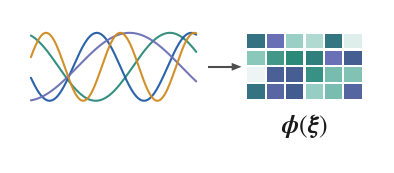

In [6]:
fig, ax = canvas(35, 12.5)
ox, oy, w, h = 0.0, 4.0, 18.0, 8.5                               # 左：随机特征（原图是一张 18 × 8.5 mm 的小图）
x = np.linspace(0, 1, 200)
for om, b, c in ((7.0, 0.4, LEARN), (11.0, 1.9, KNOWN), (5.0, 3.3, AI), (14.0, 5.0, SEARCH)):
    ax.plot(ox + 0.6 + x * (w - 1.2), oy + h / 2 + np.cos(om * x + b) * (h / 2 - 0.8), color=c, lw=0.6,
            alpha=0.95, zorder=3)
arrow(ax, (18.6, 8.25), (22.0, 8.25), INK_2, 0.6, head=1.0, width=0.8)
ox, oy = 22.4, 4.8                                               # 右：特征矩阵（12 × 7 mm），格子颜色随机取
rng = np.random.default_rng(7)
cm = LinearSegmentedColormap.from_list("phi", ["#eef6f4", "#8cc9bd", LEARN, "#3e5a8a", "#6a70b6"])
nr, nc, g = 4, 6, 0.22
cw, ch = (11.6 - g * (nc - 1)) / nc, (6.6 - g * (nr - 1)) / nr
for r in range(nr):
    for c in range(nc):
        ax.add_patch(Rectangle((ox + 0.2 + c * (cw + g), oy + 0.2 + r * (ch + g)), cw, ch,
                               fc=cm(rng.uniform(0, 1)), ec="none", zorder=3))
text(ax, ox + 6.0, 2.2, r"$\boldsymbol{\phi}(\boldsymbol{\xi})$", 7.5)
done(fig, "fig3_05_random_features")

### ⑥ 后验（中栏，34 × 17 mm，含下面的模型公式）
在几个查询点上真做一次随机特征贝叶斯回归（`rff_blr` 在公共设置里），画出均值、±2 倍标准差的色带和三条后验采样。

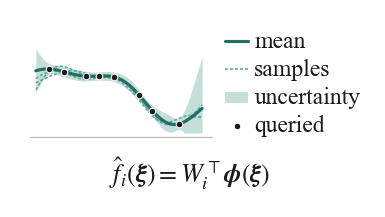

In [7]:
w, h, oy = 34, 12, 5.0                                           # 后验图 34 × 12 mm，下面留 5 mm 写公式
fig, ax = canvas(w, h + oy)
pw = 18.5
ax.plot([0.5, pw + 0.5], [oy + 0.6, oy + 0.6], color=tint(AXIS, 0.4), lw=0.35, zorder=1)
xo = np.array([0.08, 0.17, 0.3, 0.38, 0.47, 0.62, 0.7, 0.86])   # 查询过的点
f = lambda x: 0.55 * np.sin(5.5 * x + 0.3) + 0.2 * np.cos(11 * x)
yo = f(xo) + np.random.default_rng(5).normal(0, 0.05, len(xo))
xs = np.linspace(0, 1, 160)
mean, sd, draws = rff_blr(xo, yo, xs, seed=2)
X = lambda x: 1.1 + x * (pw - 1.6)
Y = lambda y: oy + h / 2 - 0.6 + y * 4.6
lo, hi = oy + 1.0, oy + h - 0.6
ax.fill_between(X(xs), np.clip(Y(mean - 2 * sd), lo, hi), np.clip(Y(mean + 2 * sd), lo, hi),
                color=tint(LEARN, 0.72), lw=0, zorder=2)          # 不确定带
for d in draws:                                                  # 后验采样：细虚线
    ax.plot(X(xs), np.clip(Y(d), lo, hi), color=tint(LEARN, 0.25), lw=0.45, ls=(0, (2.0, 1.2)), zorder=3)
ax.plot(X(xs), Y(mean), color=shade(LEARN, 0.2), lw=0.9, zorder=4)   # 后验均值：粗实线
ax.plot(X(xo), Y(yo), ls="", marker="o", ms=1.9, mfc=INK, mec="#ffffff", mew=0.3, zorder=5)
lx, ly = pw + 1.8, oy + h - 1.7                                  # 图例
ax.plot([lx, lx + 2.4], [ly, ly], color=shade(LEARN, 0.2), lw=0.9)
text(ax, lx + 3.0, ly, "mean", ha="left")
ax.plot([lx, lx + 2.4], [ly - 2.85, ly - 2.85], color=tint(LEARN, 0.25), lw=0.45, ls=(0, (2.0, 1.2)))
text(ax, lx + 3.0, ly - 2.85, "samples", ha="left")
ax.add_patch(Rectangle((lx, ly - 6.3), 2.4, 1.2, fc=tint(LEARN, 0.72), ec="none"))
text(ax, lx + 3.0, ly - 5.7, "uncertainty", ha="left")
ax.plot([lx + 1.2], [ly - 8.55], ls="", marker="o", ms=1.9, mfc=INK, mec="#ffffff", mew=0.3)
text(ax, lx + 3.0, ly - 8.55, "queried", ha="left")
text(ax, 16.75, 1.9, r"$\hat{f}_{i}(\boldsymbol{\xi}) = W_{i}^{\top}\boldsymbol{\phi}(\boldsymbol{\xi})$", 7.5)
done(fig, "fig3_06_posterior")

### ⑦ DSO 的精确计算：33 节点馈线（右中，34 × 16.5 mm）
馈线画在一叠斜着的情景层上；节点按典型日最低电压上色（越低越深），三类资源在对应母线上用圆、方、菱形标出。

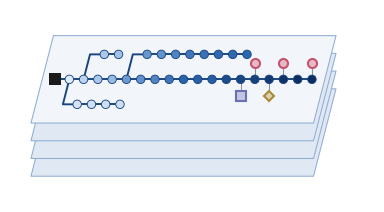

In [8]:
# IEEE 33 节点馈线：每个节点的位置（第几列, 哪一行）、下游节点、典型日最低电压（标幺值），三类资源所在的母线
POS = {0: (0, 0), 1: (1, 0), 2: (2, 0), 3: (3, 0), 4: (4, 0), 5: (5, 0), 6: (6, 0), 7: (7, 0), 8: (8, 0), 9: (9, 0),
       10: (10, 0), 11: (11, 0), 12: (12, 0), 13: (13, 0), 14: (14, 0), 15: (15, 0), 16: (16, 0), 17: (17, 0),
       18: (18, 0), 19: (2, -1), 20: (3, -1), 21: (4, -1), 22: (5, -1), 23: (3, 1), 24: (4, 1), 25: (6, 1),
       26: (7, 1), 27: (8, 1), 28: (9, 1), 29: (10, 1), 30: (11, 1), 31: (12, 1), 32: (13, 1)}
CHILDREN = {0: [1], 1: [2, 19], 2: [3, 23], 3: [4], 4: [5], 5: [6, 25], 6: [7], 7: [8], 8: [9], 9: [10], 10: [11],
            11: [12], 12: [13], 13: [14], 14: [15], 15: [16], 16: [17], 17: [18], 19: [20], 20: [21], 21: [22],
            23: [24], 25: [26], 26: [27], 27: [28], 28: [29], 29: [30], 30: [31], 31: [32]}
V_MIN = [1.0, 0.9973, 0.9843, 0.9774, 0.9705, 0.9538, 0.95, 0.9441, 0.9362, 0.9275, 0.926, 0.9233, 0.9121, 0.9078,
         0.9044, 0.9004, 0.8946, 0.8928, 0.8925, 0.9925, 0.9914, 0.9901, 0.9898, 0.9777, 0.9743, 0.9525, 0.9507,
         0.943, 0.9374, 0.9349, 0.9308, 0.93, 0.9297]
RESOURCES = {"EV": [14, 16, 18], "compute": [13], "storage": [15]}
VOLT_BLUE = LinearSegmentedColormap.from_list("volt", ["#0f2f63", "#2a64ad", "#86afdf", "#e8f0fa"])  # 电压越低越深

fig, ax = canvas(34, 16.5)
s, sk, sy = 1.45, 0.45, 1.75                                     # 每列多少毫米、往右的斜切、行距
x0, y0 = 2.4, 8.4
P = lambda x, r: np.array([x0 + s * (x + sk * (r + 1)), y0 + s * sy * (r + 1)])
for k in range(3, -1, -1):                                       # 馈线所在的平面，和下面三层情景
    a, b, c, d = P(-0.9, -1.75), P(18.9, -1.75), P(18.9, 1.75), P(-0.9, 1.75)
    off = np.array([0.0, -1.8 * k])
    ax.add_patch(Polygon([a + off, b + off, c + off, d + off], closed=True, fc=tint(KNOWN, 0.86 if k else 0.94),
                         ec=tint(KNOWN, 0.5), lw=0.3, zorder=1 + (3 - k) * 0.1, joinstyle="round"))
for a, kids in CHILDREN.items():                                 # 线路：同一行直连，换行时先走一段竖线
    for b in kids:
        pa, pb = P(*POS[a]), P(*POS[b])
        pts = [pa, pb] if POS[a][1] == POS[b][1] else [pa, P(POS[a][0], POS[b][1]), pb]
        ax.plot(*zip(*pts), color=shade(KNOWN, 0.25), lw=0.55, zorder=3, solid_joinstyle="round")
v = np.array(V_MIN)
norm = Normalize(v[1:].min(), 1.0)
for n in range(1, len(v)):                                       # 节点：按最低电压上色
    ax.add_patch(Circle(P(*POS[n]), 0.43, fc=VOLT_BLUE(norm(v[n])), ec=shade(KNOWN, 0.25), lw=0.25, zorder=4))
ax.add_patch(Rectangle(P(*POS[0]) - 0.62, 1.24, 1.24, fc=INK, ec="none", zorder=4))   # 变电站：黑方块
marks = {"EV": ("o", EV), "compute": ("s", AI), "storage": ("D", ES)}
side = {13: -1, 14: 1, 15: -1, 16: 1, 18: 1}                     # 资源标记一上一下错开
for kind, buses in RESOURCES.items():
    mk, col = marks[kind]
    for bb in buses:
        p = P(*POS[bb])
        q = p + (0, 1.7 * side.get(bb, 1))
        ax.plot(*zip(p, q), color=AXIS, lw=0.3, zorder=3.5)
        ax.plot(*q, marker=mk, ms=2.6 if mk != "D" else 2.2, mfc=tint(col, 0.6), mec=col, mew=0.6, zorder=5)
done(fig, "fig3_07_feeder")

### ⑧ 每个采样情景的柱场（右中，34 × 36 mm，y 轴朝下）
4 × 8 个情景各一根柱子：电网部分是蓝色的柱身，顶上三段薄薄的是三类聚合商的账户；越限的三根是珊瑚红；半透明的平面切在平均成本 C̄ 的高度。

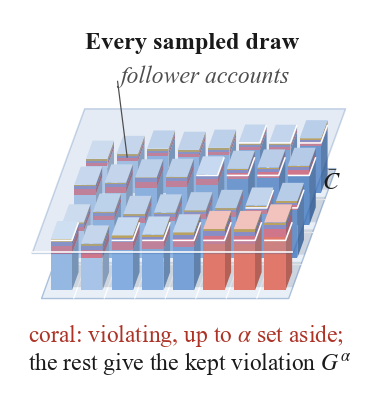

In [9]:
K, M = 4, 8                                                      # 聚合商一侧 4 种 × 电网一侧 8 种情景
LOAD = np.array([-0.9, -0.55, -0.25, 0.0, 0.2, 0.5, 0.8, 1.15])  # 电网一侧：负荷从轻到重
ACC = np.array([[0.40, 0.20, 0.12],                              # 聚合商一侧：电动汽车欠的电量、算力积压的任务、
                [0.22, 0.12, 0.08],                              # 储能要补回的电量
                [0.28, 0.17, 0.05],
                [0.16, 0.09, 0.10]])
GV = np.zeros((K, M))
GV[0, 5], GV[0, 6], GV[0, 7] = 0.30, 0.62, 1.0                   # 越限的三根：最忙的一种遇上最重的几种负荷
BODY_CMAP = LinearSegmentedColormap.from_list("body", ["#bcd2ee", "#86aedf", "#4a7bbd"])
CORAL = "#e0796b"


def clip_convex(subject, clip):
    """多边形和凸多边形求交（Sutherland–Hodgman），用来把影子裁在地板里。"""
    def inside(p, a, b):
        return (b[0] - a[0]) * (p[1] - a[1]) - (b[1] - a[1]) * (p[0] - a[0]) >= 0

    def cut(p, q, a, b):
        x1, y1, x2, y2, x3, y3, x4, y4 = *p, *q, *a, *b
        den = (x1 - x2) * (y3 - y4) - (y1 - y2) * (x3 - x4)
        t = ((x1 - x3) * (y3 - y4) - (y1 - y3) * (x3 - x4)) / den
        return (x1 + t * (x2 - x1), y1 + t * (y2 - y1))

    sign = np.sign(sum((clip[i][0] * clip[(i + 1) % len(clip)][1] - clip[(i + 1) % len(clip)][0] * clip[i][1])
                       for i in range(len(clip))))
    clip = clip if sign > 0 else clip[::-1]
    out = list(subject)
    for i in range(len(clip)):
        a, b = clip[i], clip[(i + 1) % len(clip)]
        inp, out = out, []
        for j in range(len(inp)):
            p, q = inp[j], inp[(j + 1) % len(inp)]
            if inside(q, a, b):
                if not inside(p, a, b):
                    out.append(cut(p, q, a, b))
                out.append(q)
            elif inside(p, a, b):
                out.append(cut(p, q, a, b))
        if not out:
            break
    return out


W, H = 34.0, 36.0
fig, ax = canvas(W, H, y_down=True)
DX, KX, KY = 3.1, 1.2, 3.3                                       # 每往右一列、往里一行的偏移（mm）
X0, Y0 = 2.6, 27.0
bw, bd = 0.70, 0.56                                              # 柱子的底面（占格子的比例）
acc = ACC * 0.3                                                  # 账户：柱顶上薄薄的三段
net = 0.32 + 0.30 * (LOAD[None, :] - LOAD.min()) / np.ptp(LOAD) + 0.22 * ACC.sum(1)[:, None] \
    + 0.025 * np.random.default_rng(3).standard_normal((K, M))   # 电网部分：左轻右重
total = net + acc.sum(1)[:, None]
SZ = 6.9 / total.max()
zbar = total.mean()                                               # 平均成本：半透明平面的高度


def P(m, k, z):
    return (X0 + m * DX + k * KX, Y0 - z * SZ - k * KY)


def pl(pts, fc, z, ec="none", lw=0.0, alpha=1.0):
    ax.add_patch(Polygon([P(*q) for q in pts], closed=True, fc=fc, ec=ec, lw=lw, alpha=alpha, zorder=z,
                         joinstyle="round"))


m0, m1, k0, k1 = -0.2, M - 0.1, -0.25, K - 0.25                  # 地板、格线和柔和的落地阴影（光从左前方来）
pl([(m0, k0, 0), (m1, k0, 0), (m1, k1, 0), (m0, k1, 0)], tint(KNOWN, 0.9), 0.2, ec=tint(KNOWN, 0.62), lw=0.4)
floor = [P(*q) for q in [(m0, k0, 0), (m1, k0, 0), (m1, k1, 0), (m0, k1, 0)]]
for m in range(1, M):
    q0, q1 = P(m - 0.15, k0, 0), P(m - 0.15, k1, 0)
    ax.plot([q0[0], q1[0]], [q0[1], q1[1]], color="white", lw=0.35, zorder=0.3, solid_capstyle="butt")
for k in range(1, K):
    q0, q1 = P(m0, k - 0.2, 0), P(m1, k - 0.2, 0)
    ax.plot([q0[0], q1[0]], [q0[1], q1[1]], color="white", lw=0.35, zorder=0.3, solid_capstyle="butt")
for k in range(K):
    for m in range(M):
        sh = clip_convex([P(*q) for q in [(m - 0.04, k + 0.1, 0), (m + bw + 0.26, k + 0.1, 0),
                                          (m + bw + 0.26, k + bd + 0.32, 0), (m - 0.04, k + bd + 0.32, 0)]], floor)
        if len(sh) >= 3:
            ax.add_patch(Polygon(sh, closed=True, fc=shade(KNOWN, 0.55), ec="none", alpha=0.13, zorder=0.4))


def faces(m, k, z0, z1, col, z, top):
    a0, a1, b0, b1 = m, m + bw, k, k + bd
    pl([(a1, b0, z0), (a1, b1, z0), (a1, b1, z1), (a1, b0, z1)], shade(col, 0.2), z)          # 右侧面
    pl([(a0, b0, z0), (a1, b0, z0), (a1, b0, z1), (a0, b0, z1)], col, z + 0.01)               # 正面
    if top is not None:                                          # 顶盖：柱身颜色的浅色
        pl([(a0, b0, z1), (a1, b0, z1), (a1, b1, z1), (a0, b1, z1)], tint(top, 0.55), z + 0.02)


def segments(k, m):
    """一根柱子从下往上的几段：柱身，再叠三类聚合商的账户。"""
    body = CORAL if GV[k, m] > 0 else BODY_CMAP((net[k, m] - net.min()) / (net.max() - net.min()))
    z, out = 0.0, []
    for v, col in ((net[k, m], body), (acc[k, 0], tint(EV, 0.2)), (acc[k, 1], tint(AI, 0.2)), (acc[k, 2], tint(ES, 0.2))):
        out.append((z, z + v, col))
        z += v
    return out


order = [(k, m) for k in range(K - 1, -1, -1) for m in range(M)]   # 从后往前、从左往右
for half in (0, 1):                                              # 先画平面以下的部分，再画平面以上的部分
    for n, (k, m) in enumerate(order):
        segs = segments(k, m)
        for s, (z0, z1, col) in enumerate(segs):
            lo, hi = (z0, min(z1, zbar)) if half == 0 else (max(z0, zbar), z1)
            if hi - lo <= 1e-9:
                continue
            lid = s == len(segs) - 1 and (half == 1 or z1 <= zbar)
            faces(m, k, lo, hi, col, 2 + half * 300 + n * 0.1 + s * 0.02, segs[0][2] if lid else None)
        if half == 1 and segs[0][0] < zbar < segs[-1][1]:        # 柱子穿过平面的地方画一圈白色「水线」
            q0, q1, q2 = P(m, k, zbar), P(m + bw, k, zbar), P(m + bw, k + bd, zbar)
            ax.plot([q0[0], q1[0], q2[0]], [q0[1], q1[1], q2[1]], color="white", lw=0.45,
                    zorder=2 + 300 + n * 0.1 + 0.09, solid_capstyle="butt")
    if half == 0:                                                # 平均成本处的半透明平面
        pm0, pm1, pk0, pk1 = -0.45, M + 0.1, -0.4, K + 0.05
        pl([(pm0, pk0, zbar), (pm1, pk0, zbar), (pm1, pk1, zbar), (pm0, pk1, zbar)], tint(KNOWN, 0.45), 150,
           ec=shade(KNOWN, 0.05), lw=0.45, alpha=0.22)
        q0, q1 = P(pm0, pk0, zbar), P(pm1, pk0, zbar)
        ax.plot([q0[0], q1[0]], [q0[1] - 0.12, q1[1] - 0.12], color="white", lw=0.5, zorder=151, alpha=0.9,
                solid_capstyle="butt")
        q = P(pm1, (pk0 + pk1) / 2, zbar)
        text(ax, q[0] + 0.25, q[1] + 0.2, r"$\bar{C}$", 7.0, ha="left", z=152)

text(ax, W / 2, 1.9, "Every sampled draw", 7.0, bold=True)        # 文字（原图里是 PPT 文字）
q = P(1 + bw * 0.5, K - 1, total[K - 1, 1] - acc[K - 1].sum() * 0.5)
ax.plot([q[0], 9.4], [q[1], 5.7], color=INK_2, lw=0.35, zorder=700, solid_capstyle="butt")
text(ax, 9.7, 5.3, "follower accounts", 6.8, color=INK_2, italic=True, ha="left", z=701)
text(ax, 0.3, 31.6, r"coral: violating, up to $\alpha$ set aside;", 6.8, color=shade(VIOL, 0.1), ha="left")
text(ax, 0.3, 34.4, r"the rest give the kept violation $G^{\alpha}$", 6.8, ha="left")
done(fig, "fig3_08_every_sampled_draw")

### ⑨ 后验采样（右上，42 × 15 mm）
左边是权重的后验（三层椭圆）和抽到的三组权重，右边是它们各自对应的响应曲线。

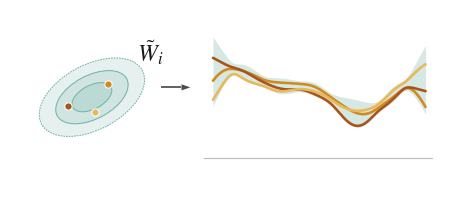

In [10]:
w, h = 42, 15
fig, ax = canvas(w, h)
cx, cy = 6.8, 7.6
for k, (sx, sy) in enumerate(((11.6, 6.6), (8.0, 4.4), (4.4, 2.4))):   # 三层椭圆，最外层是虚线
    ax.add_patch(Ellipse((cx, cy), sx, sy, angle=28, fc=tint(LEARN, 0.88 - 0.1 * k), ec=tint(LEARN, 0.35),
                         lw=0.3, ls=(0, (1.6, 1.0)) if k == 0 else "-", zorder=2 + k))
draw_cols = (SEARCH, "#a8541a", "#e9b85a")
for p, c in zip([(cx + 1.6, cy + 1.3), (cx - 2.4, cy - 0.9), (cx + 0.3, cy - 1.5)], draw_cols):   # 抽到的三组权重
    ax.plot(*p, marker="o", ms=2.1, mfc=c, mec="#ffffff", mew=0.3, zorder=6)
text(ax, cx + 4.6, cy + 4.6, r"$\tilde W_i$", ha="left")
arrow(ax, (13.8, 8.6), (16.8, 8.6), INK_2, 0.5)
x0, pw = 18.2, w - 18.8                                          # 右边：后验的不确定带和三条采样曲线
ax.plot([x0, x0 + pw], [1.4, 1.4], color=tint(AXIS, 0.4), lw=0.35, zorder=1)
xo = np.array([0.1, 0.24, 0.41, 0.55, 0.78, 0.9])
f = lambda x: 0.5 * np.sin(6.0 * x + 0.8) + 0.2 * np.cos(13 * x)
xs = np.linspace(0, 1, 160)
mean, sd, _ = rff_blr(xo, f(xo), xs, sigma=0.08, seed=4)
X = lambda x: x0 + 0.9 + x * (pw - 1.6)
Y = lambda y: 1.4 + h / 2 - 0.4 + y * 3.6
lo, hi = 1.8, h - 0.5
ax.fill_between(X(xs), np.clip(Y(mean - 2 * sd), lo, hi), np.clip(Y(mean + 2 * sd), lo, hi),
                color=tint(LEARN, 0.8), lw=0, zorder=2)
rng = np.random.default_rng(8)
for k, c in enumerate(draw_cols):
    d = mean + sd * (1.4 * np.sin(4 * xs + 2.1 * k) + 0.3 * rng.normal())
    ax.plot(X(xs), np.clip(Y(d), lo, hi), color=c, lw=0.75, zorder=3 + k * 0.1)
done(fig, "fig3_09_posterior_sampling")

### ⑩ 代理搜索（右上，42 × 17 mm）
每个后验样本一张代理地形（后面两张只露出边）；地形是两个高斯坑加一点波纹画成的等高线，差分进化的种群往最近的坑底走。

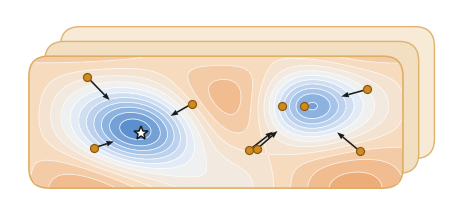

In [11]:
LAND_CMAP = LinearSegmentedColormap.from_list("land", ["#4f86c9", "#a6c4e8", "#eef3f8", "#f7dcc0", "#eaa56c"])
w, h = 42, 17
fig, ax = canvas(w, h)
lw_, lh, off, rr = w - 4.0, h - 3.6, np.array([1.6, 1.5]), 2.0
for k in (2, 1):                                                 # 后面两张：其他后验样本的地形
    o = off * k + 0.4
    ax.add_patch(FancyBboxPatch(tuple(o), lw_, lh, boxstyle=f"round,pad=0,rounding_size={rr}",
                                fc=tint(SEARCH, 0.62 + 0.1 * k), ec=tint(SEARCH, 0.35), lw=0.4, zorder=1 + (2 - k)))
x0, y0 = 0.4, 0.4
X, Y = np.meshgrid(np.linspace(x0, x0 + lw_, 380), np.linspace(y0, y0 + lh, 150))
u, v = (X - x0) / lw_, (Y - y0) / lh
Z = (1.0 - 1.0 * np.exp(-(((u - 0.30) / 0.16) ** 2 + ((v - 0.42) / 0.30) ** 2))   # 两个坑加一点波纹
     - 0.8 * np.exp(-(((u - 0.74) / 0.12) ** 2 + ((v - 0.62) / 0.26) ** 2))
     + 0.25 * np.sin(u * 9) * np.cos(v * 5))
dx = np.maximum(np.abs(X - (x0 + lw_ / 2)) - (lw_ / 2 - rr), 0)  # 只保留圆角矩形里面的部分
dy = np.maximum(np.abs(Y - (y0 + lh / 2)) - (lh / 2 - rr), 0)
Zm = np.where(dx ** 2 + dy ** 2 <= rr ** 2, Z, np.nan)
ax.contourf(X, Y, Zm, levels=14, cmap=LAND_CMAP, zorder=3)
ax.contour(X, Y, Zm, levels=14, colors="#ffffff", linewidths=0.25, alpha=0.8, zorder=3.1)
ax.add_patch(FancyBboxPatch((x0, y0), lw_, lh, boxstyle=f"round,pad=0,rounding_size={rr}", fc="none",
                            ec=tint(SEARCH, 0.3), lw=0.45, zorder=6))
rng = np.random.default_rng(21)                                  # 种群：每个点往最近的坑底走一步
pop = np.column_stack([x0 + rng.uniform(0.08, 0.92, 9) * lw_, y0 + rng.uniform(0.15, 0.85, 9) * lh])
tgt = np.array([[x0 + 0.30 * lw_, y0 + 0.42 * lh], [x0 + 0.74 * lw_, y0 + 0.62 * lh]])
for p in pop:
    t = tgt[np.argmin(((tgt - p) ** 2).sum(1))]
    q = p + 0.42 * (t - p)
    if np.hypot(*(q - p)) > 1.6:
        arrow(ax, p, q, INK, 0.45, head=0.75, width=0.55, z=4)
    ax.plot(*p, marker="o", ms=2.3, mfc=SEARCH, mec=shade(SEARCH, 0.35), mew=0.35, zorder=5)
ax.plot(*tgt[0], marker="*", ms=4.2, mfc="#ffffff", mec=INK, mew=0.45, zorder=5)
done(fig, "fig3_10_surrogate_search")

### ⑪ 候选批次（右栏，39 × 8 mm）
原图里是 PPT 画的圆角框和一排圆点，这里用 matplotlib 画同样的样子。

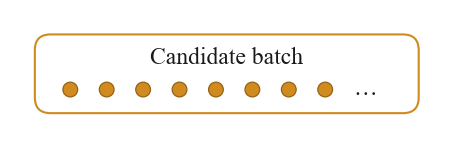

In [12]:
fig, ax = canvas(41, 10)
ax.add_patch(FancyBboxPatch((1, 1), 39, 8, boxstyle="round,pad=0,rounding_size=1.6", fc="#ffffff", ec=SEARCH, lw=0.6))
text(ax, 20.5, 6.6, "Candidate batch")
for k in range(8):                                               # 一批候选信号
    ax.add_patch(Circle((4.6 + 3.7 * k, 3.4), 0.75, fc=SEARCH, ec=shade(SEARCH, 0.3), lw=0.35))
text(ax, 34.6, 3.5, "…")
done(fig, "fig3_11_candidate_batch")

### ⑫ 排好序的查询信号（右下，44.8 × 25.8 mm）
每个查询过的信号立成一根柱子，柱顶铺着它的加价热力图：可行的按期望成本从低到高排，不可行的（珊瑚红）放在另一块底座上，按越限量排；最好的那根描一圈发光的边。

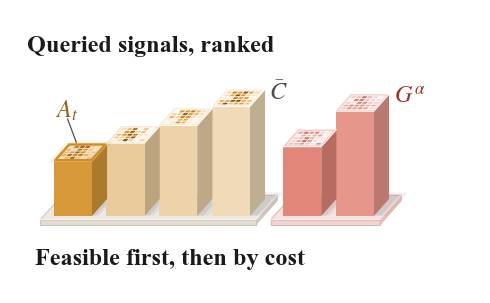

In [13]:
VIOL_CMAP = LinearSegmentedColormap.from_list("viol", ["#fbefee", "#f1c7c2", "#e19a92", "#c86f66"])
CORAL = "#e0796b"
NORM = Normalize(0, ABAR)


def signal(seed, nb=5):
    """一个示意的加价信号（5 × 6），铺在柱顶上。"""
    rng = np.random.default_rng(seed)
    base = np.array([0.03, 0.08, 0.12, 0.09, 0.05, 0.02])
    return np.clip(base[None, :] + rng.normal(0, 0.035, (nb, 6)), 0, ABAR)


def heat(ax, pr, x, d, z, w, dep, A, cmap, norm, zo, m=0.22, lw=0.18):
    """平铺在高度 z 处的热力图：A 的行往里（第 0 行在最前），列沿 x，四周留 m 的边。"""
    nr, nc = A.shape
    cw, cd = (w - 2 * m) / nc, (dep - 2 * m) / nr
    for r in range(nr):
        for c in range(nc):
            x0, d0 = x + m + c * cw, d + m + r * cd
            poly(ax, pr.quad(x0, x0 + cw, d0, d0 + cd, z), cmap(norm(A[r, c])), zo, ec="white", lw=lw)


def rim(ax, pr, x, d, z, w, dep, color, lw, zo):
    """给柱顶描一圈发光的边：外面先铺两层淡淡的光晕，再描实线。"""
    for g, a in ((0.55, 0.10), (0.3, 0.16)):
        poly(ax, pr.quad(x - g, x + w + g, d - g, d + dep + g, z), tint(color, 0.2), zo - 0.02, alpha=a)
    poly(ax, pr.quad(x, x + w, d, d + dep, z), "none", zo, ec=color, lw=lw)


fig, ax = canvas(44.8, 25.8)
pr = Pr(2.4, 6.3, 0.55, 0.62)
FEAS = np.array([0.30, 0.45, 0.60, 0.76])                        # 可行信号的期望成本，从低到高
INF = np.array([0.42, 0.72])                                     # 不可行信号的越限量，从低到高
pw, pdp, pitch = 3.9, 2.8, 5.35
xf = [0.5 + pitch * k for k in range(len(FEAS))]
xi = [xf[-1] + pitch + 1.9 + pitch * k for k in range(len(INF))]
hgt = lambda v: 2.0 + 12.0 * v
for (a, b), top_c, side_c, edge in (((-0.5, xf[-1] + pw + 0.9), "#eee9e2", "#d9d0c4", "#cfc4b5"),       # 两块底座
                                    ((xi[0] - 0.9, xi[-1] + pw + 0.9), "#f7e4e0", "#e8c4bd", "#e0b3ab")):
    box(ax, pr, a, -0.6, -0.55, b - a, pdp + 1.2, 0.55, top_c, 1, top=top_c, front=mix(top_c, side_c, 0.5),
        side=side_c, ec=edge, lw=0.3, hl=True)
zo = 3.0
items = [(x, v, "f", k) for k, (x, v) in enumerate(zip(xf, FEAS))] + \
        [(x, v, "v", k) for k, (x, v) in enumerate(zip(xi, INF))]
for x, v, kind, k in sorted(items, key=lambda it: -it[0]):       # 从右往左画：右边柱子的侧面会被左边的挡住
    hz = hgt(v)
    is_best = kind == "f" and k == 0
    body = (mix(SEARCH, "white", 0.12) if is_best else mix(SEARCH, "white", 0.5 + 0.06 * k)) if kind == "f" \
        else mix(CORAL, "white", 0.1 + 0.12 * k)
    shadow(ax, pr, x, 0, pw, pdp, hz, 2.0, k=0.12, alpha=0.13)
    box(ax, pr, x, 0, 0, pw, pdp, hz, body, zo, top=tint(body, 0.55))
    heat(ax, pr, x, 0, hz, pw, pdp, signal((60 if kind == "f" else 80) + k),
         ADDER_CMAP if kind == "f" else VIOL_CMAP, NORM, zo + 0.1, m=0.28)
    if is_best:
        rim(ax, pr, x + 0.12, 0.12, hz, pw - 0.24, pdp - 0.24, SEARCH, 0.65, zo + 0.2)
    zo += 1
q = pr(xf[0] + pw / 2, pdp / 2, hgt(FEAS[0]))
line(ax, [(q[0] - 0.4, q[1] + 1.0), (q[0] - 1.3, q[1] + 3.4)], INK_2, 0.35, 40)
text(ax, q[0] - 1.45, q[1] + 4.35, r"$A_t$", 7.0, color=shade(SEARCH, 0.3))
qf = pr(xf[-1] + pw, pdp, hgt(FEAS[-1]))
text(ax, qf[0] + 0.45, qf[1] - 0.3, r"$\bar{C}$", 7.0, color=INK_2, ha="left")
qi = pr(xi[-1] + pw, pdp, hgt(INF[-1]))
text(ax, qi[0] + 0.45, qi[1] - 0.3, r"$G^{\alpha}$", 7.0, color=shade(VIOL, 0.15), ha="left")
text(ax, 0.23, 23.625, "Queried signals, ranked", 7.0, bold=True, ha="left")   # 这两行原图里是 PPT 文字
text(ax, 1.02, 1.95, "Feasible first, then by cost", 7.0, bold=True, ha="left")
done(fig, "fig3_12_ranked_signals")

### ⑬ 底部：滚动时域的决策曲面（179 × 16.4 mm，直接用 PPT 上的坐标，y 轴朝下）
横向是做决策的时刻（往左越早），往里是信号覆盖的未来几个小时，高度是加价。每个小四边形按法线和光线的夹角调亮度；t 处竖起的半透明截面就是 A_t，只有它的第一个小时生效。

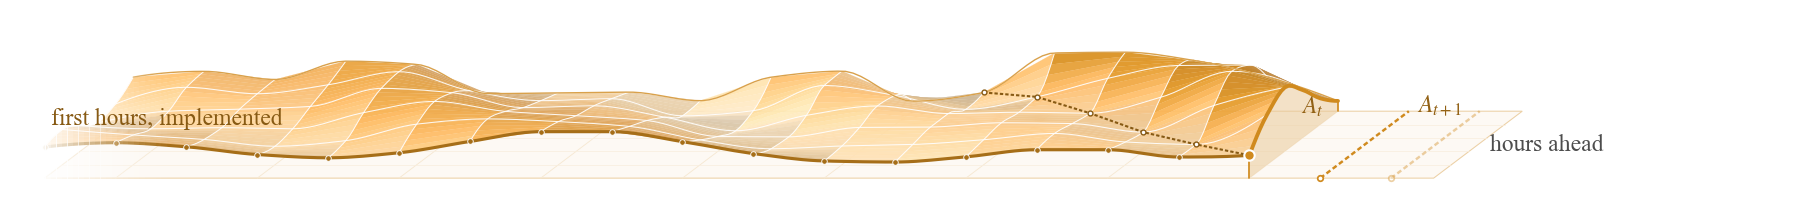

In [14]:
from scipy.interpolate import PchipInterpolator

GB = dict(ND=18, Wd=7.2, DX=9.0, DY=6.8, HZ=58.0, yF=117.4, D3=12.0)   # 18 个决策时刻；每个往右 7.2 mm
GB["xt"] = 140.4 - GB["DX"]                                      # 「宣布」的箭头落在 A_t 的远端


def proj(d, k, z):
    """d：决策时刻（0 = 现在 t，负数更早）；k：往前看第几个小时（0–5，往里）；z：加价。"""
    return np.array([GB["xt"] + d * GB["Wd"] + k / 5 * GB["DX"], GB["yF"] - k / 5 * GB["DY"] - z * GB["HZ"]])


def final_value(tau):
    """t + tau 这个小时最后定下来的加价：t 之前是已经执行的，t 及之后是 A_t 的计划（各母线取平均）。"""
    if tau >= 0:
        return (list(A_SHOW.mean(0)) + [0.03, 0.05])[int(tau)]
    return (0.022 + 0.062 * np.exp(-((tau + 9.5) / 2.4) ** 2) + 0.03 * np.exp(-((tau + 2.5) / 1.8) ** 2)
            + 0.04 * np.exp(-((tau + 16.0) / 2.2) ** 2))


def plan(d, k):
    """在 t + d 时刻定下的信号，给 t + d + k 这个小时计划的加价：离得越近，改得越少。"""
    tau = d + k
    if d == 0 or k == 0:
        return final_value(tau)
    wave = np.sin(1.25 * d + 0.8 * tau) * 0.7 + np.sin(0.45 * d - 1.7 * tau + 0.6) * 0.3
    return float(np.clip(final_value(tau) + 0.026 * (k / 5) ** 0.8 * wave, 0.003, ABAR))


fig, ax = canvas(179.0, 16.4, y_down=True, x0=7.0, y0=101.8)
ND = GB["ND"]
D = np.arange(-ND + 1, 1)
Kh = np.arange(6)
Kf = np.linspace(0, 5, 26)
Z = np.array([PchipInterpolator(Kh, [plan(d, k) for k in Kh])(Kf) for d in D])   # （决策时刻, 细分的 k）
pg = lambda pts, **kw: ax.add_patch(Polygon(np.asarray(pts), closed=True, **kw))

pg([proj(D[0], 0, 0), proj(2.6, 0, 0), proj(2.6, 5, 0), proj(D[0], 5, 0)], fc=tint(SEARCH, 0.95),   # 地板和浅网格
   ec=tint(SEARCH, 0.6), lw=0.3, zorder=1)
for d in D[1::2]:
    ax.plot(*zip(proj(d, 0, 0), proj(d, 5, 0)), color=tint(SEARCH, 0.8), lw=0.25, zorder=1.1)
for k in (1, 2, 3, 4):
    ax.plot(*zip(proj(D[0], k, 0), proj(2.6, k, 0)), color=tint(SEARCH, 0.85), lw=0.2, zorder=1.1)

light = np.array([-0.45, -0.55, 0.70])                           # 曲面：每个小四边形按法线和光的夹角调亮度
light /= np.linalg.norm(light)
P3 = lambda d, k, z: np.array([d * GB["Wd"], k / 5 * GB["D3"], z * GB["HZ"]])
for j in range(len(Kf) - 2, -1, -1):
    for i in range(len(D) - 1):
        c3 = [P3(D[i], Kf[j], Z[i, j]), P3(D[i + 1], Kf[j], Z[i + 1, j]),
              P3(D[i + 1], Kf[j + 1], Z[i + 1, j + 1]), P3(D[i], Kf[j + 1], Z[i, j + 1])]
        nrm = np.cross(c3[1] - c3[0], c3[3] - c3[0])
        lam = max(0.0, float(nrm @ light / np.linalg.norm(nrm)))
        base = np.array(to_rgb(ADDER_CMAP(Normalize(0, 0.13)(Z[i:i + 2, j:j + 2].mean()))))
        rgb = np.clip(base * (0.80 + 0.30 * lam), 0, 1)
        q = [proj(D[i], Kf[j], Z[i, j]), proj(D[i + 1], Kf[j], Z[i + 1, j]),
             proj(D[i + 1], Kf[j + 1], Z[i + 1, j + 1]), proj(D[i], Kf[j + 1], Z[i, j + 1])]
        pg(q, fc=rgb, ec=rgb, lw=0.05, alpha=0.93, zorder=2 + (len(Kf) - j) * 0.001)
df = np.linspace(D[0], 0, 160)
for k in range(1, 6):                                            # 白色网格：「往前看几个小时」相同的线
    zk = PchipInterpolator(D, Z[:, 5 * k])(df)
    p = np.array([proj(d, k, z) for d, z in zip(df, zk)])
    ax.plot(p[:, 0], p[:, 1], color="#ffffff", lw=0.3, alpha=0.9, zorder=2.2)
for i, d in enumerate(D[:-1]):                                   # 每个信号一条线
    p = np.array([proj(d, k, z) for k, z in zip(Kf, Z[i])])
    ax.plot(p[:, 0], p[:, 1], color="#ffffff", lw=0.3, alpha=0.9, zorder=2.2)
bk = np.array([proj(d, 5, z) for d, z in zip(df, PchipInterpolator(D, Z[:, -1])(df))])
ax.plot(bk[:, 0], bk[:, 1], color=tint(SEARCH, 0.2), lw=0.4, zorder=2.25)   # 远处的边
z0 = PchipInterpolator(D, Z[:, 0])(df)                           # 前沿：每个信号的第一个小时，也就是实际执行的
p = np.array([proj(d, 0, z) for d, z in zip(df, z0)])
ax.plot(p[:, 0], p[:, 1], color=shade(SEARCH, 0.2), lw=0.9, zorder=3)
for i, d in enumerate(D[:-1]):
    ax.plot(*proj(d, 0, Z[i, 0]), marker="o", ms=1.6, mfc=shade(SEARCH, 0.2), mec="#ffffff", mew=0.25, zorder=3.1)
pts = np.array([proj(-m, m, plan(-m, m)) for m in range(5, -1, -1)])   # 虚线：同一个小时 t 被六个信号反复计划
ax.plot(pts[:, 0], pts[:, 1], color=shade(SEARCH, 0.35), lw=0.6, ls=(0, (1.6, 1.0)), zorder=3.3)
ax.plot(pts[:-1, 0], pts[:-1, 1], ls="none", marker="o", ms=1.4, mfc="#ffffff", mec=shade(SEARCH, 0.35), mew=0.4,
        zorder=3.4)
sl = np.array([proj(0, k, z) for k, z in zip(Kf, Z[-1])])        # A_t：在 t 处竖起的半透明截面
fl = np.array([proj(0, k, 0) for k in Kf])
pg(np.vstack([sl, fl[::-1]]), fc=tint(SEARCH, 0.55), alpha=0.55, ec="none", zorder=3.5)
ax.plot(sl[:, 0], sl[:, 1], color=SEARCH, lw=1.1, zorder=3.6)
for a, b in ((sl[0], fl[0]), (sl[-1], fl[-1])):
    ax.plot(*zip(a, b), color=SEARCH, lw=0.5, zorder=3.6)
ax.plot(*sl[0], marker="o", ms=3.0, mfc=SEARCH, mec="#ffffff", mew=0.6, zorder=3.8)   # 只有第一个小时生效
for m, a_ in ((1, 1.0), (2, 0.4)):                               # A_{t+1}、A_{t+2} 将来竖起的位置
    ax.plot(*zip(proj(m, 0, 0), proj(m, 5, 0)), color=SEARCH, lw=0.7, ls=(0, (2.0, 1.2)), alpha=a_, zorder=1.3)
    ax.plot(*proj(m, 0, 0), marker="o", ms=1.6, mfc="#ffffff", mec=SEARCH, mew=0.5, alpha=a_, zorder=1.35)
xa, xb = proj(D[0], 0, 0)[0] - 0.5, proj(D[0] + 1.8, 0, 0)[0]    # 最左边渐渐淡出：最早的小时进了档案
for k in range(24):
    ax.add_patch(Rectangle((xa + k * (xb - xa) / 24, 102.0), (xb - xa) / 24 + 0.03, GB["yF"] + 0.4 - 102.0,
                           fc="#ffffff", alpha=0.96 * (1 - (k + 0.5) / 24) ** 1.3, ec="none", zorder=9))
end, e1 = proj(0, 5, plan(0, 5)), proj(1, 5, 0)                  # 文字（原图里是 PPT 文字）
text(ax, end[0] - 1.5, end[1] + 0.6, r"$A_t$", color=shade(SEARCH, 0.3), ha="right")
text(ax, e1[0] + 0.8, e1[1] - 0.6, r"$A_{t+1}$", color=shade(SEARCH, 0.3), ha="left")
text(ax, proj(-ND + 1, 0, 0)[0] + 0.6, GB["yF"] - 6.0, "first hours, implemented", color=shade(SEARCH, 0.35),
     ha="left", z=10)
ka = proj(2.6, 2.5, 0)
text(ax, ka[0] + 1.2, ka[1], "hours ahead", color=INK_2, ha="left")
done(fig, "fig3_13_hourly_operation")

## Fig. 1 双层结构图

整张图是一个场景：地板上竖着一排玻璃切片（下层：聚合商在每个价格下的成本），上面浮着 DSO 的成本台阶（上层）。玻璃是用 numpy 做图像处理合成的 600 dpi 图片，其余都是矢量。

**这一节要按顺序运行**：后面几格会用到前面定义的函数。

### ⓪ 模型和几何（这一格不画图）
下层是一个线性规划：价格越高，聚合商越往后推，最优响应是一段段台阶；上层 DSO 的成本在提前充电时最低，但会破坏电压限值。

In [15]:
from scipy.ndimage import distance_transform_edt, gaussian_filter, map_coordinates

LEV = np.array([0.86, 0.58, 0.44, 0.16])                         # 四个可能的最优响应 y*
THR = np.array([0.24, 0.50, 0.72])                               # 价格到这几处，线性规划换顶点
YV = 0.66                                                        # 电压限值：y 超过它就越限


def lp_value(a, y):
    """下层成本 J(a, y)（分段线性）。"""
    f = np.zeros(np.broadcast(a, y).shape)
    for j in range(1, len(LEV)):
        f = f + (a - THR[j - 1]) * np.clip(y - LEV[j], 0.0, LEV[j - 1] - LEV[j])
    return f


def best(a):
    """价格 a 下的最优响应 y*(a)。"""
    return LEV[np.searchsorted(THR, a)]


def dso_cost(y):
    """上层：DSO 对响应 y 的成本。越早充电越便宜，但会破坏电压限值。"""
    return 0.55 * (y - 0.95) ** 2 + 0.05


W1, H1, DPI1 = 90.0, 96.0, 600                                   # 整张图 90 × 96 mm，y 轴朝下
YLO, YHI = LEV.min(), LEV.max()
AK = np.array([0.05, 0.18, 0.32, 0.46, 0.60, 0.75, 0.92])        # 画成切片的 7 个价格
ZS, H0, LIFT = 0.30, 0.06, 0.66                                  # 切片最高多高、最低处的厚度、上层离地多高
YY = np.unique(np.concatenate([np.linspace(YLO, YHI, 160), LEV]))
GMAX = max((lp_value(a, YY) - lp_value(a, best(a))).max() for a in AK)
NAVY, GOLD, LAV, LINK, INK2 = "#1f3a5f", "#f3c64b", "#8f90c4", "#c3a46a", "#4d4d4d"


def P1(a, y, z):
    """斜投影：价格 a 往右上，决策 y 往右，高度 z 往上（y 轴朝下的毫米坐标）。"""
    x0, y0, sy, sz, kx, ky = 24.0, 86.0, 47.0, 42.0, 12.0, 30.0   # 原点；y、z 每单位多少毫米；价格往右、往上偏多少
    return (x0 + sy * (y - YLO) / (YHI - YLO) + kx * a, y0 - sz * z - ky * a)


def zu(y):                                                       # 上层画在多高
    return LIFT + 0.8 * dso_cost(y)


def slice_height(a):
    """切片的上沿：最低处的厚度，加上每个 y 比最优响应多花的成本。"""
    return H0 + (lp_value(a, YY) - lp_value(a, best(a))) / GMAX * ZS


def slice_outline(a):
    g = slice_height(a)
    return [P1(a, y, h) for y, h in zip(YY, g)] + [P1(a, y, 0) for y in YY[::-1]]


def crop_canvas(x0, y0, x1, y1):
    """只显示 (x0, y0)–(x1, y1) 这一块的画布（y 轴朝下）。"""
    return canvas(x1 - x0, y1 - y0, y_down=True, x0=x0, y0=y0)


print("Fig. 1 的模型和几何已定义")

Fig. 1 的模型和几何已定义


### ① 地板（矢量）
上下渐变的底色、越限一侧的浅红底和斜线、白色网格、电压限值虚线。渐变是用一张小图片裁成地板的形状铺上去的。

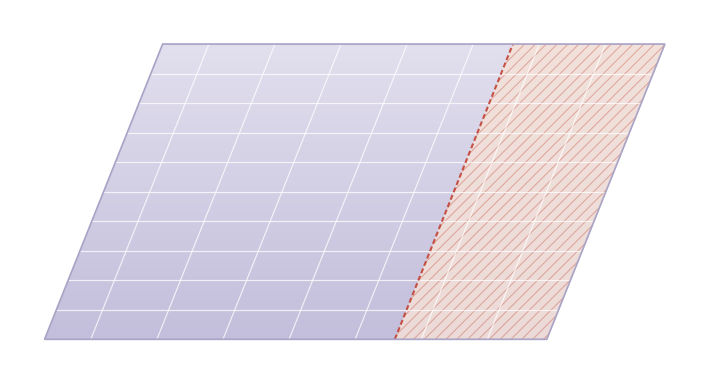

In [16]:
def vgrad(ax, pts, c_top, c_bot, z=0.0):
    """上下渐变填满多边形：画一张渐变的小图片，再用多边形把它裁出来。"""
    pts = np.asarray(pts)
    x0, x1 = pts[:, 0].min(), pts[:, 0].max()
    yt, yb = pts[:, 1].min(), pts[:, 1].max()
    t = np.linspace(0, 1, 256)[:, None, None]
    img = np.array(to_rgb(c_top))[None, None] * (1 - t) + np.array(to_rgb(c_bot))[None, None] * t
    im = ax.imshow(np.repeat(img, 2, axis=1), extent=(x0, x1, yb, yt), origin="upper", interpolation="bicubic",
                   zorder=z)
    im.set_clip_path(Polygon(pts, closed=True, transform=ax.transData))


def draw_floor(ax):
    fl = [P1(0, YLO - 0.03, 0), P1(1, YLO - 0.03, 0), P1(1, YHI + 0.03, 0), P1(0, YHI + 0.03, 0)]
    vgrad(ax, fl, "#e2dfee", "#c3bedb")
    bad = [P1(0, YV, 0), P1(1, YV, 0), P1(1, YHI + 0.03, 0), P1(0, YHI + 0.03, 0)]   # 越限的一侧：浅红底
    ax.add_patch(Polygon(bad, closed=True, fc="#f6e2d6", ec="none", alpha=0.8, zorder=1))
    clip = Polygon(bad, closed=True, transform=ax.transData)                       # 斜线只画在越限区里
    xb, yb_ = np.array(bad)[:, 0], np.array(bad)[:, 1]
    for c in np.arange(xb.min() - (yb_.max() - yb_.min()), xb.max(), 1.1):
        ln, = ax.plot([c, c + (yb_.max() - yb_.min())], [yb_.max(), yb_.min()], color=VIOL, lw=0.3, alpha=0.35,
                      zorder=1.2)
        ln.set_clip_path(clip)
    for y in np.arange(0.2, 0.81, 0.1):                                            # 白网格：透过玻璃能看到它被折弯
        q0, q1 = P1(0, y, 0), P1(1, y, 0)
        ax.plot([q0[0], q1[0]], [q0[1], q1[1]], color="white", lw=0.35, alpha=0.75, zorder=1.5)
    for a in np.arange(0.1, 0.91, 0.1):
        q0, q1 = P1(a, YLO - 0.03, 0), P1(a, YHI + 0.03, 0)
        ax.plot([q0[0], q1[0]], [q0[1], q1[1]], color="white", lw=0.35, alpha=0.75, zorder=1.5)
    q0, q1 = P1(0, YV, 0), P1(1, YV, 0)                                            # 电压限值
    ax.plot([q0[0], q1[0]], [q0[1], q1[1]], color=VIOL, lw=0.6, ls=(0, (2.4, 1.4)), alpha=0.85, zorder=2)
    ax.add_patch(Polygon(fl, closed=True, fc="none", ec="#aaa4c6", lw=0.5, zorder=2))


fig, ax = crop_canvas(20, 54, 87, 88)
draw_floor(ax)
ax.set_xlim(20, 87); ax.set_ylim(88, 54)                         # imshow 会改坐标范围，改回来
done(fig, "fig1_01_floor")

### ② 玻璃切片（图像处理合成，600 dpi，要跑十几秒）
从最远的一片开始：先画地板，再一片片往上叠。每叠一片，就把当前画面当作「玻璃后面的景物」，依次做模糊、边缘折射、提亮染色、边缘高光；玻璃在地板上还有一块模糊的影子。最优响应的小球、地板上的路径、连到上层的虚线，也按前后顺序叠进去。

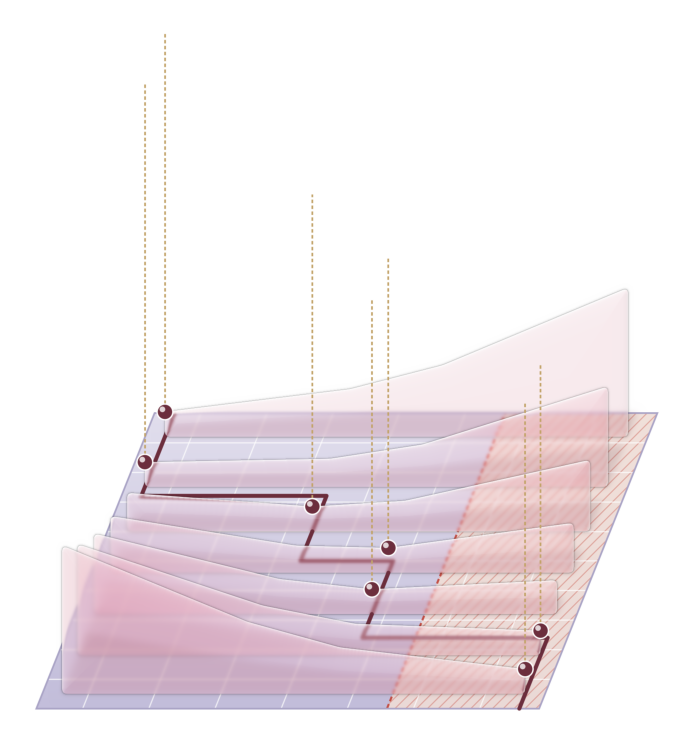

In [17]:
PX1 = DPI1 / 25.4                                                # 每毫米多少像素
BLUR = 0.14 * PX1                                                # 透过玻璃看到的东西模糊多少
LENS_W, LENS_K = 0.8 * PX1, 0.6 * PX1                            # 边缘折射的宽度和最大偏移
RIM, GLOW = 0.11 * PX1, 1.4 * PX1                                # 边缘高光的宽度、里面柔光的宽度
ROUND = 0.25 * PX1                                               # 圆角
LIGHT = np.array([-0.5, -0.866])                                 # 光从左上来（x, y 向下）
GLASS = tint(EV, 0.45)                                           # 玻璃的颜色：聚合商的粉色


def raster(draw):
    """把 draw(ax) 画的东西变成整页大小的 RGBA 数组（0–1，第 0 行在最上面），背景透明。"""
    fig = plt.figure(figsize=(W1 / 25.4, H1 / 25.4), dpi=DPI1)
    fig.patch.set_alpha(0)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.patch.set_alpha(0)
    draw(ax)
    ax.set_xlim(0, W1); ax.set_ylim(H1, 0); ax.set_aspect("equal"); ax.axis("off")
    fig.canvas.draw()
    out = np.asarray(fig.canvas.buffer_rgba(), dtype=np.float32) / 255.0
    plt.close(fig)
    return out


class Layers:
    """一层层往上叠（预乘 alpha 的 over 运算），从最远的开始。"""

    def __init__(self, shape):
        self.pm = np.zeros(shape[:2] + (3,), np.float32)
        self.a = np.zeros(shape[:2], np.float32)

    def over(self, rgb, a, region=(slice(None), slice(None))):
        self.pm[region] = rgb * a[..., None] + self.pm[region] * (1 - a[..., None])
        self.a[region] = a + self.a[region] * (1 - a)

    def put(self, rgba):
        self.over(rgba[..., :3], rgba[..., 3])

    def seen(self, region):
        """region 里现在看起来的样子（放在白纸上）。"""
        return self.pm[region] + (1 - self.a[region])[..., None]

    def rgba(self):
        a = self.a[..., None]
        return np.dstack([np.where(a > 1e-4, self.pm / np.maximum(a, 1e-4), 1.0), self.a])


def liquid_glass(cv, mask, tint_rgb, tint_w=0.28, frost=0.13):
    """在 mask（0–1 的覆盖度）的位置盖一片玻璃。"""
    ys, xs = np.nonzero(mask > 0.004)
    mg = int(LENS_K + 3 * BLUR) + 4
    region = (slice(max(ys.min() - mg, 0), ys.max() + mg + 1), slice(max(xs.min() - mg, 0), xs.max() + mg + 1))
    msk = np.clip((gaussian_filter(mask[region], ROUND) - 0.5) * 2.5 * ROUND + 0.5, 0, 1)   # 圆角
    d = distance_transform_edt(msk >= 0.5).astype(np.float32)    # 每个像素离边缘多远
    gy, gx = np.gradient(gaussian_filter(d, 1.5))
    nn = np.hypot(gx, gy) + 1e-6
    nx, ny = -gx / nn, -gy / nn                                  # 指向边缘外侧的方向
    seen = cv.seen(region)                                       # ① 磨砂：后面的景物模糊
    blur = np.dstack([gaussian_filter(seen[..., c], BLUR) for c in range(3)])
    free = 1 - np.clip((ny - 0.6) / 0.3, 0, 1)                   # 底边立在地板上，那里不折射、不打高光
    t = np.clip(1 - d / LENS_W, 0, 1) ** 2 * free                # ② 折射：越靠边，越从外侧借像素
    yy, xx = np.mgrid[0:msk.shape[0], 0:msk.shape[1]].astype(np.float32)
    at = [yy + ny * LENS_K * t, xx + nx * LENS_K * t]
    g = np.dstack([map_coordinates(blur[..., c], at, order=1, mode="nearest") for c in range(3)])
    g = 1 - (1 - g) * (1 - frost)                                # ③ 提亮、加饱和、染色
    lum = g.mean(axis=2, keepdims=True)
    g = np.clip(lum + (g - lum) * 1.3, 0, 1)
    g = g * (1 - tint_w) + np.asarray(to_rgb(tint_rgb), np.float32) * tint_w
    facing = nx * LIGHT[0] + ny * LIGHT[1]                       # ④ 高光：朝光和背光的边最亮，朝光的边里面带柔光
    rimv = np.exp(-d / RIM) * (0.25 + 0.75 * np.abs(facing) ** 1.5) * free
    glow = np.exp(-d / GLOW) * np.clip(facing, 0, 1) * 0.30
    shade_ = np.exp(-d / (3 * RIM)) * np.clip(-facing, 0, 1) * 0.10 * free
    g = (g + (1 - g) * np.clip(1.1 * rimv + glow, 0, 1)[..., None]) * (1 - shade_[..., None])
    dout = distance_transform_edt(msk < 0.5).astype(np.float32)  # ⑤ 外面一圈淡淡的细线，让亮边看起来是「边」
    hair = np.exp(-dout / (0.07 * PX1)) * (msk < 0.5) * 0.45
    cv.over(np.zeros(hair.shape + (3,), np.float32), hair.astype(np.float32), region)
    cv.over(g.astype(np.float32), (msk * 0.97).astype(np.float32), region)


def draw_path(ax, lo, hi):
    """地板上的最优响应路径 y*(a)，价格从 lo 到 hi 的一段，在换顶点处跳一下。"""
    cuts = np.unique(np.concatenate([[0.0, 1.0], THR, AK]))
    for a0, a1 in zip(cuts[:-1], cuts[1:]):
        if a0 < lo - 1e-9 or a1 > hi + 1e-9:
            continue
        yb = best(0.5 * (a0 + a1))
        p0, p1 = P1(a0, yb, 0), P1(a1, yb, 0)
        xs, ys = [p0[0], p1[0]], [p0[1], p1[1]]
        if np.any(np.isclose(a1, THR)):
            p2 = P1(a1, best(a1 + 1e-9), 0)
            xs.append(p2[0])
            ys.append(p2[1])
        ax.plot(xs, ys, color=shade(EV, 0.45), lw=1.15, solid_capstyle="round", solid_joinstyle="round")


def draw_front_of(ax, a):
    """紧贴在切片 a 前面的东西：它的最优响应（带高光的小球）和连到上层的虚线。"""
    yb = best(a)
    q, qu = P1(a, yb, H0), P1(a, yb, zu(yb))
    ax.plot([q[0], qu[0]], [q[1] - 0.8, qu[1]], color=LINK, lw=0.5, ls=(0, (2.0, 1.4)))
    ax.add_patch(Circle(q, 0.8, fc=shade(EV, 0.45), ec="white", lw=0.4, zorder=5))
    ax.add_patch(Circle((q[0] - 0.26, q[1] - 0.26), 0.29, fc="white", ec="none", alpha=0.8, zorder=6))


def render_scene():
    """地板、切片、路径和连线，从后往前合成。"""
    lay = raster(draw_floor)
    cv = Layers(lay.shape)
    cv.put(lay)
    order = list(AK[::-1])                                       # 从最远（价格最高）的切片开始
    cv.put(raster(lambda ax: draw_path(ax, order[0], 1.0)))
    fl = [P1(0, YLO - 0.03, 0), P1(1, YLO - 0.03, 0), P1(1, YHI + 0.03, 0), P1(0, YHI + 0.03, 0)]
    for k, a in enumerate(order):
        g = slice_height(a)                                      # 玻璃的影子：往后拖到地板上，模糊，淡淡的粉色
        cast = [P1(a, y, 0) for y in YY] + [P1(a + 0.55 * h + 0.01, y, 0) for y, h in zip(YY[::-1], g[::-1])]

        def draw_shadow(ax, cast=cast):
            pg = ax.add_patch(Polygon(cast, closed=True, fc="black", ec="none"))
            pg.set_clip_path(Polygon(fl, closed=True, transform=ax.transData))      # 只落在地板上

        sh = gaussian_filter(raster(draw_shadow)[..., 3], 0.35 * PX1) * 0.16
        cv.over(np.broadcast_to(np.asarray(to_rgb(shade(EV, 0.5)), np.float32), sh.shape + (3,)), sh)
        mask = raster(lambda ax: ax.add_patch(Polygon(slice_outline(a), closed=True, fc="white", ec="none")))
        liquid_glass(cv, mask[..., 3], GLASS, tint_w=0.22 + 0.12 * k / (len(order) - 1))   # 越靠前的玻璃颜色越深
        nxt = order[k + 1] if k + 1 < len(order) else 0.0
        cv.put(raster(lambda ax: (draw_front_of(ax, a), draw_path(ax, nxt, a))))
    return cv.rgba()


scene = render_scene()                                           # (高, 宽, 4)，透明背景
page = scene[..., :3] * scene[..., 3:] + (1 - scene[..., 3:])    # 放到白纸上看
rr_, cc_ = np.nonzero(scene[..., 3] > 0.01)                      # 只显示有东西的那一块
x0, x1, y0, y1 = cc_.min() / PX1 - 1, cc_.max() / PX1 + 1, rr_.min() / PX1 - 1, rr_.max() / PX1 + 1
fig, ax = crop_canvas(x0, y0, x1, y1)
ax.imshow(page, extent=(0, W1, H1, 0), interpolation="antialiased", zorder=0)
ax.set_xlim(x0, x1); ax.set_ylim(y1, y0)
done(fig, "fig1_02_glass_scene", svg=False)

### ③ 上层：DSO 的成本台阶（矢量）
把地板上的最优响应路径抬到上层，高度是 DSO 的成本；越限的一段是红色。每个价格一个带高光的小球，不越限里最便宜的那个换成金色的星。

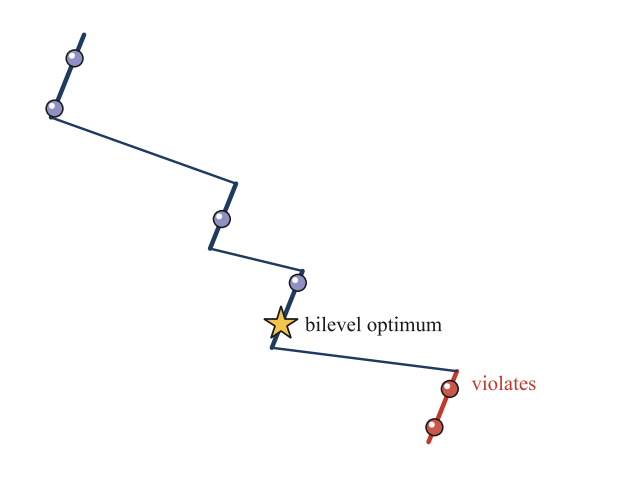

In [18]:
def draw_upper(ax):
    for a0, a1 in zip(np.r_[0.0, THR], np.r_[THR, 1.0]):          # 每段价格对应一个最优响应，画成一段平台
        yb = best(0.5 * (a0 + a1))
        q0, q1 = P1(a0, yb, zu(yb)), P1(a1, yb, zu(yb))
        ax.plot(*zip(q0, q1), color=VIOL if yb > YV else NAVY, lw=1.3, solid_capstyle="round", zorder=60)
        if a1 < 1.0:                                             # 换顶点处的跳变
            y2 = best(a1 + 1e-9)
            ax.plot(*zip(q1, P1(a1, y2, zu(y2))), color=NAVY, lw=0.7, solid_capstyle="round", zorder=60)
    tops = {a: best(a) for a in AK}
    pts = [P1(a, tops[a], zu(tops[a])) for a in AK]
    kb = min((k for k in range(len(AK)) if tops[AK[k]] <= YV), key=lambda k: dso_cost(tops[AK[k]]))   # 双层最优
    for k, (a, q) in enumerate(zip(AK, pts)):
        if k == kb:
            continue
        ax.add_patch(Circle(q, 0.85, fc=tint(VIOL, 0.15) if tops[a] > YV else LAV, ec=INK, lw=0.45, zorder=61))
        ax.add_patch(Circle((q[0] - 0.27, q[1] - 0.27), 0.3, fc="#ffffff", ec="none", zorder=61.5))   # 高光点
    ax.plot(*pts[kb], marker="*", ms=3.6 * 2.83, mfc=GOLD, mec=INK, mew=0.5, zorder=62)
    text(ax, pts[kb][0] + 2.4, pts[kb][1] + 0.2, "bilevel optimum", 6.0, ha="left", halo=True)
    text(ax, pts[1][0] + 2.2, pts[1][1] - 0.4, "violates", 6.0, color=VIOL, ha="left", halo=True)


fig, ax = crop_canvas(30, 14, 90, 60)
draw_upper(ax)
done(fig, "fig1_03_upper_level")

### ④ 合成整张图（90 × 96 mm）
玻璃场景当底图，叠上上层、坐标轴和两段说明文字。

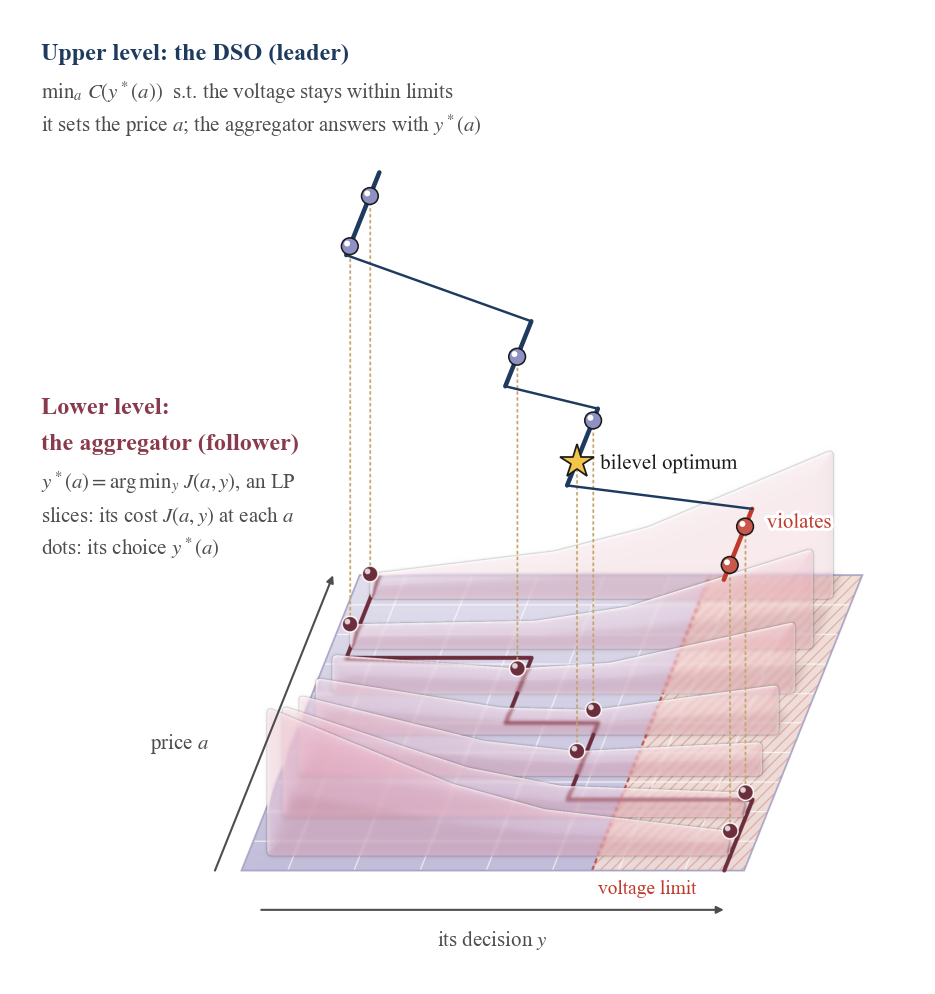

In [19]:
fig, ax = canvas(W1, H1, y_down=True)
ax.imshow(page, extent=(0, W1, H1, 0), interpolation="antialiased", zorder=0)
ax.set_xlim(0, W1); ax.set_ylim(H1, 0)
draw_upper(ax)
head = dict(arrowstyle="-|>", color=INK2, lw=0.6, shrinkA=0, shrinkB=0, mutation_scale=4.2)
a0_, a1_ = P1(0.0, YLO - 0.07, 0), P1(1.0, YLO - 0.07, 0)          # 坐标轴：价格 a、聚合商的决策 y
ax.annotate("", xy=a1_, xytext=a0_, arrowprops=head, zorder=60)
text(ax, a0_[0] - 0.6, (a0_[1] + a1_[1]) / 2 + 2.0, "price $a$", 6.0, color=INK2, ha="right")
b0_, b1_ = P1(0, YLO, -0.095), P1(0, YHI, -0.095)
ax.annotate("", xy=b1_, xytext=b0_, arrowprops=head, zorder=60)
text(ax, (b0_[0] + b1_[0]) / 2, b0_[1] + 3.0, "its decision $y$", 6.0, color=INK2)
qv = P1(0, YV, 0)
text(ax, qv[0] + 0.6, qv[1] + 1.8, "voltage limit", 5.6, color=VIOL, ha="left")
text(ax, 1.6, 3.0, "Upper level: the DSO (leader)", 7.0, bold=True, color=NAVY, ha="left")   # 两层各自的说明
text(ax, 1.6, 6.9, r"$\mathrm{min}_a\ C(y^*(a))$  s.t. the voltage stays within limits", 6.0, color=INK2, ha="left")
text(ax, 1.6, 10.2, r"it sets the price $a$; the aggregator answers with $y^*(a)$", 6.0, color=INK2, ha="left")
yl = 39.0
text(ax, 1.6, yl, "Lower level:", 7.0, bold=True, color=shade(EV, 0.3), ha="left")
text(ax, 1.6, yl + 3.6, "the aggregator (follower)", 7.0, bold=True, color=shade(EV, 0.3), ha="left")
text(ax, 1.6, yl + 7.6, r"$y^*(a) = \mathrm{arg\,min}_y\ J(a,y)$, an LP", 6.0, color=INK2, ha="left")
text(ax, 1.6, yl + 10.9, "slices: its cost $J(a,y)$ at each $a$", 6.0, color=INK2, ha="left")
text(ax, 1.6, yl + 14.2, r"dots: its choice $y^*(a)$", 6.0, color=INK2, ha="left")
done(fig, "fig1_04_full")

## Fig. 2 决策地形图

地形用的是模型真实算出来的结果：在两个加价信号 A¹、A² 张成的平面上取 241 × 241 个组合 θ₁A¹ + θ₂A²，每个都算了期望成本，以及 32 个情景里有几个越限。数据在 `data/fig2_landscape.npz`。

**这一节也要按顺序运行。**

### ⓪ 读数据、定相机（这一格不画图）

In [20]:
D2 = np.load("data/fig2_landscape.npz")
grid, cost, share = D2["grid"], D2["cost"], D2["share"]          # θ 的取值（0–1.5）、期望成本、越限情景的比例
n2 = grid.size                                                  # 241
EDGES = {ax_: {k: D2[f"edge_{ax_}_{k}"] for k in ("ev", "ai", "es")} for ax_ in ("x", "y")}   # 哪类聚合商在这条格线上换顶点
NVIOL = {k: int(D2[f"n_{k}"]) for k in ("zero", "A1", "A2", "blend")}                       # 几个标注点各有几个情景越限
W2, H2 = 90.0, 80.0
OK_CMAP = LinearSegmentedColormap.from_list("ok", ["#f3f2fa", "#c9c8e6", "#8f90c4", "#5b5d9c"])   # 可接受：淡紫到深紫
BAD_CMAP = LinearSegmentedColormap.from_list("bad", ["#fbe3e6", "#f0b3bc", "#e07f8e"])            # 被排除：粉红
CLASS_EDGE = {"ev": "#a01d43", "ai": "#27358f", "es": "#8a6a12"}
NAVY, GOLD, LAV, AMBER, GREY, INK2 = "#1f3a5f", "#f3c64b", "#8f90c4", "#c98a1c", "#8b909a", "#4d4d4d"


class Camera:
    """正交投影：绕竖轴转 az 度、俯视 el 度；返回 y 朝下的毫米坐标。"""

    def __init__(self, az, el, scale, origin):
        self.ca, self.sa = np.cos(np.radians(az)), np.sin(np.radians(az))
        self.ce, self.se = np.cos(np.radians(el)), np.sin(np.radians(el))
        self.s, self.o = scale, np.asarray(origin, float)

    def depth(self, x, y):                                       # 越大越远
        return x * self.sa + y * self.ca

    def __call__(self, x, y, z):
        u = x * self.ca - y * self.sa
        v = (x * self.sa + y * self.ca) * self.se + z * self.ce
        return self.o[0] + self.s * u, self.o[1] - self.s * v


az, s_ = 42.0, 57.0
cam = Camera(az=az, el=25.0, scale=s_, origin=(W2 / 2 - s_ * (np.cos(np.radians(az)) - np.sin(np.radians(az))) / 2, 75.2))
ok = share <= 0.1 + 1e-9                                         # 32 个情景里最多 3 个越限：可接受
un = (cost - cost.min()) / (cost.max() - cost.min())
zs = 0.008 + 0.30 * un                                           # 高度：期望成本
cols = np.where(ok[..., None], OK_CMAP(0.06 + 0.88 * un)[..., :3], BAD_CMAP(0.12 + 0.78 * un)[..., :3])
print(f"{n2} × {n2} 个信号，其中 {int(ok.sum())} 个可接受")

241 × 241 个信号，其中 26225 个可接受


### ① 顶部：领导者–跟随者这一圈（90 × 13 mm）
DSO 发出信号 → 三类聚合商响应 → 馈线在随机情景下算潮流 → 期望成本和越限比例回到 DSO（虚线）。

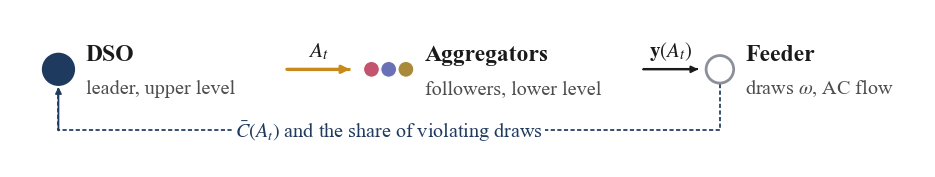

In [21]:
def arrow2(ax, pts, color, lw, head, dash=None):
    """折线，最后一段带箭头。"""
    xs, ys = zip(*pts)
    ax.plot(xs, ys, color=color, lw=lw, ls=(0, dash) if dash else "-", zorder=60, solid_capstyle="butt")
    ax.annotate("", xy=pts[-1], xytext=pts[-2], zorder=60,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=lw, shrinkA=0, shrinkB=0, mutation_scale=head * 2.8))


def draw_game(ax):
    yg = 4.6
    ax.add_patch(Circle((3.4, yg), 1.6, fc=NAVY, ec=NAVY, lw=0.5, zorder=61))                 # DSO
    text(ax, 6.2, yg - 1.5, "DSO", 6.8, bold=True, ha="left")
    text(ax, 6.2, yg + 1.9, "leader, upper level", 5.8, color=INK2, ha="left")
    arrow2(ax, [(26.6, yg), (33.0, yg)], AMBER, 0.9, 1.6)                                      # 信号 A_t
    text(ax, 29.8, yg - 1.9, "$A_t$", 6.2)
    for k, c in enumerate((EV, AI, ES)):                                                      # 三类聚合商
        ax.add_patch(Circle((35.2 + 1.75 * k, yg), 0.8, fc=c, ec="#ffffff", lw=0.3, zorder=61))
    text(ax, 40.6, yg - 1.5, "Aggregators", 6.8, bold=True, ha="left")
    text(ax, 40.6, yg + 1.9, "followers, lower level", 5.8, color=INK2, ha="left")
    arrow2(ax, [(62.8, yg), (68.4, yg)], INK, 0.6, 1.4)                                        # 响应 y(A_t)
    text(ax, 65.6, yg - 1.9, r"$\mathbf{y}(A_t)$", 6.0)
    ax.add_patch(Circle((70.6, yg), 1.4, fc="#ffffff", ec=GREY, lw=0.8, zorder=61))            # 馈线
    text(ax, 73.2, yg - 1.5, "Feeder", 6.8, bold=True, ha="left")
    text(ax, 73.2, yg + 1.9, r"draws $\omega$, AC flow", 5.8, color=INK2, ha="left")
    yr = yg + 6.2                                                                               # 虚线回到 DSO
    arrow2(ax, [(70.6, yg + 1.5), (70.6, yr), (3.4, yr), (3.4, yg + 1.8)], NAVY, 0.5, 1.3, dash=(2.4, 1.4))
    text(ax, 37.0, yr, r"$\bar{C}(A_t)$ and the share of violating draws", 5.8, color=NAVY,
         bbox=dict(fc="#ffffff", ec="none", pad=0.4))


fig, ax = canvas(W2, 13, y_down=True)
draw_game(ax)
done(fig, "fig2_01_game")

### ② 图例（90 × 11 mm）

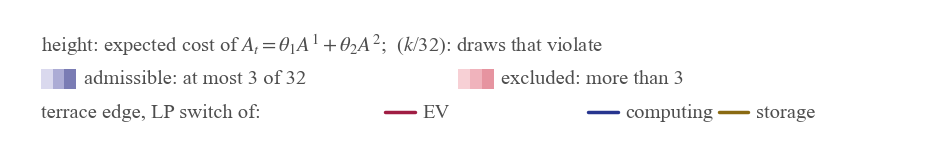

In [22]:
def draw_legend(ax):
    y1 = 15.6
    text(ax, 1.6, y1, r"height: expected cost of $A_t=\theta_1 A^1+\theta_2 A^2$;  ($k$/32): draws that violate", 5.9,
         color=INK2, ha="left")
    y2 = y1 + 3.4
    for j in range(3):                                           # 三格渐变色块
        ax.add_patch(Rectangle((1.6 + 1.2 * j, y2 - 1.0), 1.2, 2.0, fc=OK_CMAP(0.2 + 0.3 * j), ec="none", zorder=8))
        ax.add_patch(Rectangle((44.0 + 1.2 * j, y2 - 1.0), 1.2, 2.0, fc=BAD_CMAP(0.2 + 0.3 * j), ec="none", zorder=8))
    text(ax, 6.0, y2, "admissible: at most 3 of 32", 5.9, color=INK2, ha="left")
    text(ax, 48.4, y2, "excluded: more than 3", 5.9, color=INK2, ha="left")
    y3 = y2 + 3.4
    text(ax, 1.6, y3, "terrace edge, LP switch of:", 5.9, color=INK2, ha="left")
    for x, (k, lab) in zip((36.6, 57.2, 70.5), (("ev", "EV"), ("ai", "computing"), ("es", "storage"))):
        ax.plot([x, x + 3.0], [y3, y3], color=CLASS_EDGE[k], lw=1.0, solid_capstyle="round", zorder=60)
        text(ax, x + 3.8, y3, lab, 5.9, color=INK2, ha="left")


fig, ax = canvas(W2, 11, y_down=True, y0=13.5)
draw_legend(ax)
done(fig, "fig2_02_legend")

### ③ 地形：58,081 根平顶小柱子（90 × 58 mm）
每个信号一根柱子，高度是期望成本，颜色分可接受（紫）和被排除（粉）。从远到近画，比邻居高的一侧才画出墙；相邻两个信号之间，哪一类聚合商的线性规划换了顶点，就用那一类的颜色描出这条台阶边。几万个多边形放进一个 PolyCollection，画得快。

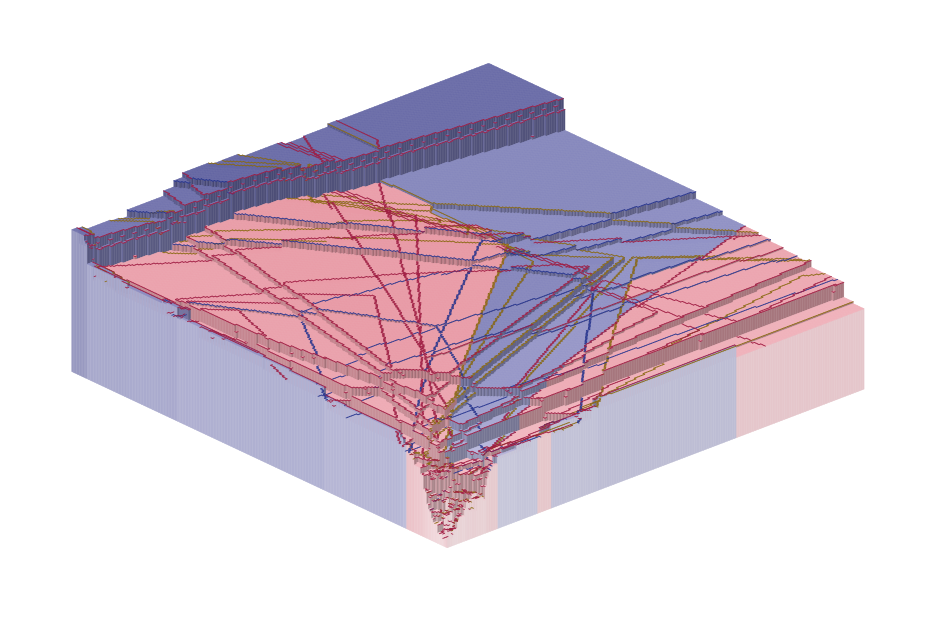

In [23]:
from matplotlib.collections import LineCollection, PolyCollection


def terraces(ax, Z, colours, dark=(0.16, 0.30), base=0.0, side=(0.30, 0.42)):
    """Z (n, n) 是 [0,1]² 上的高度，colours (n, n, 3) 是顶面颜色；从远到近画。"""
    n = Z.shape[0]
    d = 1.0 / n
    I, J = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    order = np.argsort(-(cam.depth((I + .5) * d, (J + .5) * d)).ravel(), kind="stable")
    polys, fcs = [], []
    Zp = np.pad(Z, 1, constant_values=base)
    for k in order:
        i, j = divmod(int(k), n)
        x0, y0, h = i * d, j * d, Z[i, j]
        c = colours[i, j]
        hl = Zp[i, j + 1]                                        # -x 方向的邻居：比它矮，就画出这面墙
        if hl < h - 1e-9:
            polys.append([cam(x0, y0 + d, h), cam(x0, y0, h), cam(x0, y0, hl), cam(x0, y0 + d, hl)])
            fcs.append(tint(shade(c, 0.05), side[0]) if i == 0 else shade(c, dark[0]))
        hf = Zp[i + 1, j]                                        # -y 方向的邻居
        if hf < h - 1e-9:
            polys.append([cam(x0, y0, h), cam(x0 + d, y0, h), cam(x0 + d, y0, hf), cam(x0, y0, hf)])
            fcs.append(tint(shade(c, 0.12), side[1]) if j == 0 else shade(c, dark[1]))
        polys.append([cam(x0, y0, h), cam(x0 + d, y0, h), cam(x0 + d, y0 + d, h), cam(x0, y0 + d, h)])   # 顶面
        fcs.append(tuple(c))
    pc = PolyCollection(polys, facecolors=fcs, edgecolors=fcs, linewidths=0.12, zorder=2)
    pc.set_rasterized(True)                                      # 存 SVG 时这一层用图片，否则文件有几十 MB
    ax.add_collection(pc)


def draw_edges(ax, lw=0.26, alpha=0.9):
    """三类聚合商的台阶边线，每类一个 LineCollection。"""
    d = 1.0 / n2
    for k in ("es", "ai", "ev"):
        segs = []
        for i, j in zip(*np.nonzero(EDGES["x"][k])):             # (i, j) 和 (i+1, j) 之间的边
            h = max(zs[i, j], zs[i + 1, j])
            segs.append([cam((i + 1) * d, j * d, h), cam((i + 1) * d, (j + 1) * d, h)])
        for i, j in zip(*np.nonzero(EDGES["y"][k])):             # (i, j) 和 (i, j+1) 之间的边
            h = max(zs[i, j], zs[i, j + 1])
            segs.append([cam(i * d, (j + 1) * d, h), cam((i + 1) * d, (j + 1) * d, h)])
        lc = LineCollection(segs, colors=[CLASS_EDGE[k]], linewidths=lw, zorder=40, capstyle="round", alpha=alpha)
        lc.set_rasterized(True)
        ax.add_collection(lc)


fig, ax = canvas(W2, 58, y_down=True, y0=22)
terraces(ax, zs, cols)
draw_edges(ax)
done(fig, "fig2_03_terrain")

### ④ 地形上的标注，合成整张图（90 × 80 mm）
几个关键信号各立一根针：零信号、A¹、A²、两者的混合（红点）、可接受里最便宜的（金星）；虚线是 A² 到 A¹ 的直线混合。最后把顶部示意和图例也画上。

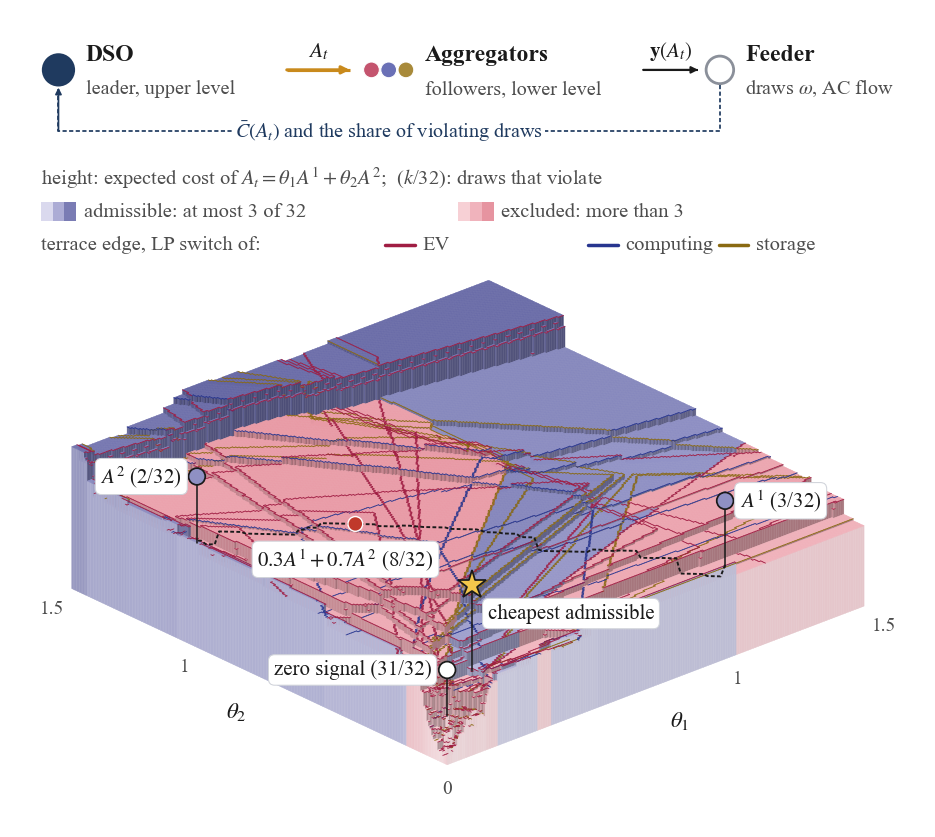

In [24]:
umax = grid[-1]
P2 = lambda u, v, z: cam(u / umax, v / umax, z)                  # θ₁、θ₂ 的实际取值 → 画布坐标
idx = lambda u: min(n2 - 1, int(round(u / umax * (n2 - 1))))
zat = lambda u, v: zs[idx(u), idx(v)]
LABEL = dict(boxstyle="round,pad=0.25,rounding_size=0.3", fc="#ffffff", ec="#d0d3da", lw=0.3)


def pin(ax, u, v, lift, kind, label, dx, dy, ha):
    """从地形上竖起一根针，顶上放小球或星，旁边写标签。"""
    z0 = zat(u, v)
    a_, b_ = P2(u, v, z0), P2(u, v, z0 + lift)
    ax.plot(*zip(a_, b_), color=INK, lw=0.45, zorder=60)
    if kind == "star":
        ax.plot(*b_, marker="*", ms=3.0 * 2.83, mfc=GOLD, mec=INK, mew=0.5, zorder=62)
    else:
        ax.add_patch(Circle(b_, 0.85, fc=kind, ec=INK, lw=0.5, zorder=61))
    text(ax, b_[0] + dx, b_[1] + dy, label, 6.0, ha=ha, bbox=LABEL, z=63)


def draw_marks(ax):
    ib, jb = np.unravel_index(np.argmin(np.where(ok, cost, np.inf)), cost.shape)   # 可接受里最便宜的
    ts = np.linspace(0.0, 1.0, 120)
    ax.plot(*zip(*[P2(1 - t, t, zat(1 - t, t) + 0.004) for t in ts]), color=INK, lw=0.55, ls=(0, (2.0, 1.2)),
            zorder=60)
    pin(ax, 0.0, 0.0, 0.09, "#FFFFFF", f"zero signal ({NVIOL['zero']}/32)", -1.6, 0, "right")
    pin(ax, 1.0, 0.0, 0.13, LAV, f"$A^1$ ({NVIOL['A1']}/32)", 1.5, 0, "left")
    pin(ax, 0.0, 1.0, 0.13, LAV, f"$A^2$ ({NVIOL['A2']}/32)", -1.5, 0, "right")
    pin(ax, grid[ib], grid[jb], 0.17, "star", "cheapest admissible", 1.6, 2.9, "left")
    bx, by = P2(0.3, 0.7, zat(0.3, 0.7) + 0.004)                                   # 0.3A¹ + 0.7A²
    ax.add_patch(Circle((bx, by), 0.75, fc=VIOL, ec="#FFFFFF", lw=0.4, zorder=61))
    text(ax, bx - 1.0, by + 3.6, f"$0.3A^1+0.7A^2$ ({NVIOL['blend']}/32)", 6.0, bbox=LABEL, z=63)
    a_ = P2(0, 0, 0)                                                               # 地板上的刻度和坐标名
    text(ax, a_[0], a_[1] + 2.4, "0", 5.6, color=INK2)
    for t in (1.0, 1.5):
        a_, b_ = P2(t, 0, 0), P2(0, t, 0)
        text(ax, a_[0] + 0.8, a_[1] + 2.0, f"{t:g}", 5.6, color=INK2, ha="left")
        text(ax, b_[0] - 0.8, b_[1] + 2.0, f"{t:g}", 5.6, color=INK2, ha="right")
    a_, b_ = P2(0, 0, 0), P2(umax, 0, 0)
    text(ax, (a_[0] + b_[0]) / 2 + 2.4, (a_[1] + b_[1]) / 2 + 3.6, r"$\theta_1$", 6.6)
    a_, b_ = P2(0, 0, 0), P2(0, umax, 0)
    text(ax, (a_[0] + b_[0]) / 2 - 2.4, (a_[1] + b_[1]) / 2 + 3.6, r"$\theta_2$", 6.6)


fig, ax = canvas(W2, H2, y_down=True)
terraces(ax, zs, cols)
draw_edges(ax)
draw_marks(ax)
draw_game(ax)
draw_legend(ax)
done(fig, "fig2_04_full")

## 改成自己的图

- 先定画布：组件在论文里多宽多高，就开多大的 `canvas(w, h)`，坐标全用毫米。
- 立体感靠三件事：斜投影算出每个面的四个角点、从后往前画、顶面掺白侧面掺黑。
- 示意数据写成简单的函数（正弦、高斯）就够了，图上不放具体数值；需要真实数据的（像 Fig. 2）就读真实结果。
- 每画一版就渲染出来看一眼，再改参数。